# EDA na Prática

Nas aulas 9 e 10 vimos os quatro princípios da EDA (estrutural, distribucional, relacional e detecção de outliers/anomalias), como tratar dados ausentes e outliers, e como fazer análise descritiva, bivariada e multivariada. Hoje é a hora de **aplicarmos na prática**. Durante a primeira hora da aula, serão apresentadas as técnicas no dataset *Heart Disease* (UCI) e depois **cada aluno** irá aplicar as técnicas no dataset que foi escolhido semana passada.

*Relembrando*: a EDA não é uma linha reta

A EDA costuma ser apresentada como uma sequência de etapas (estrutura → tratamento → descrição → relação), mas na prática ela é **iterativa**: às vezes tratamos um outlier, olhamos a estatística descritiva de novo, e percebemos que precisa voltar atrás. Hoje vamos deixar isso explícito: olhamos a estatística descritiva **antes** de tratar dados ausentes/outliers (pra saber *como* tratar) e **depois** (pra confirmar o efeito do tratamento).

## Como funcionará a atividade

- **Duração:** ~1h40min
- **Formato:** individual
- **Passo 1:** acompanhem a demonstração no dataset Heart Disease.
- **Passo 2:** importem o dataset que vocês escolheram e enviaram anteriormente.
- **Passo 3:** repliquem o mesmo ciclo no dataset escolhido, respondendo às perguntas guiadas.
- **Uso de IA:** permitido, conforme o Plano de Ensino — documentem na seção final.

## Setup de Bibliotecas e Dados

In [ ]:
!pip install pandas numpy matplotlib seaborn scipy kagglehub
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (12, 5)

COR_NEUTRA = "lightgray"     # convenção: cinza-claro pra tudo que é "pano de fundo" genérico
COR_CONTEXTO = "#e9d4d0"    # rosa-claro pra pano de fundo / classe de referência
COR_DESTAQUE = "#2d223a"    # roxo pra classe de interesse / "o personagem da história"
COR_ALERTA = "tab:red"       # exceção deliberada: outliers/pontos de atenção

## Carregando o Dataset

In [ ]:
import kagglehub
import os
import pandas as pd

# Download latest version
path = kagglehub.dataset_download("leofire123/indian-flight-delay-datasets")

print("Path to dataset files:", path)
print(os.listdir(path))

variavel = os.path.join(path, 'india_flight_delay_model_input.csv')
print(variavel)

df = pd.read_csv(variavel)
df.head()

100%|██████████| 4.73M/4.73M [00:00<00:00, 44.7MB/s]

Extracting files...


Path to dataset files: /root/.cache/kagglehub/datasets/leofire123/indian-flight-delay-datasets/versions/1
['india_flight_delay_model_input.csv']
/root/.cache/kagglehub/datasets/leofire123/indian-flight-delay-datasets/versions/1/india_flight_delay_model_input.csv


,Flight_Date,Airline,Flight_Number,Origin_Airport,Destination_Airport,Scheduled_Departure_Hour,Scheduled_Departure_Minute,Day_of_Week,Month,Is_Weekend,...,Humidity_pct,Wind_Speed_kmh,Visibility_km,Rainfall_mm,Cloud_Cover_pct,Origin_Congestion_Index,Previous_Flight_Delay_Minutes,Turnaround_Risk_Index,Departure_Delay,Delay_Target
0,2025-12-04,IndiGo,IN8723,BOM,DEL,13,57,3,12,0,...,46.1,4.3,9.8,5.2,0.0,63.5,0,23.9,43,1
1,2024-01-15,IndiGo,IN558,CCU,HYD,19,14,0,1,0,...,70.5,8.9,11.7,0.4,39.8,95.3,1,31.5,49,1
2,2023-11-06,Vistara,VI4949,HYD,DEL,8,50,0,11,0,...,53.7,7.8,9.6,4.3,16.6,100.0,1,41.5,73,1
3,2025-08-08,SpiceJet,SP3196,BLR,DIB,11,56,4,8,0,...,42.0,1.5,12.6,4.6,23.6,51.1,1,28.2,40,1
4,2023-09-09,IndiGo,IN8458,BLR,JGA,22,59,5,9,1,...,58.5,1.3,11.3,3.5,36.2,67.0,0,27.9,0,0


## 1. Princípio Estrutural

Antes de qualquer análise, precisamos entender a "anatomia" dos dados: quantas linhas e colunas temos, que tipo de dado cada coluna guarda, se há valores faltantes e se há duplicadas.

**Antes de rodar:** o Heart Disease tem 13 variáveis preditoras (idade, sexo, tipo de dor no peito, pressão em repouso, colesterol, entre outras) mais o alvo (`num`, presença/grau de doença cardíaca). Quantas linhas vocês esperam que um dataset clínico como esse tenha — dezenas, centenas ou milhares de pacientes?

### Dimensão e Tipos de Dados

In [ ]:
df.shape

(150000, 23)

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 150000 entries, 0 to 149999
Data columns (total 23 columns):
 #   Column                         Non-Null Count   Dtype  
---  ------                         --------------   -----  
 0   Flight_Date                    150000 non-null  object 
 1   Airline                        150000 non-null  object 
 2   Flight_Number                  150000 non-null  object 
 3   Origin_Airport                 150000 non-null  object 
 4   Destination_Airport            150000 non-null  object 
 5   Scheduled_Departure_Hour       150000 non-null  int64  
 6   Scheduled_Departure_Minute     150000 non-null  int64  
 7   Day_of_Week                    150000 non-null  int64  
 8   Month                          150000 non-null  int64  
 9   Is_Weekend                     150000 non-null  int64  
 10  Peak_Hour                      150000 non-null  int64  
 11  Weather                        150000 non-null  object 
 12  Temperature_C                 

In [ ]:
df.describe()

,Scheduled_Departure_Hour,Scheduled_Departure_Minute,Day_of_Week,Month,Is_Weekend,Peak_Hour,Temperature_C,Humidity_pct,Wind_Speed_kmh,Visibility_km,Rainfall_mm,Cloud_Cover_pct,Origin_Congestion_Index,Previous_Flight_Delay_Minutes,Turnaround_Risk_Index,Departure_Delay,Delay_Target
count,150000.000000,150000.000000,150000.000000,150000.000000,150000.000000,150000.00000,150000.000000,150000.000000,150000.000000,150000.000000,150000.000000,150000.000000,150000.000000,150000.000000,150000.000000,150000.000000,150000.000000
mean,14.001260,29.533773,2.997107,6.512973,0.286820,0.47528,27.028051,56.332991,5.993765,10.891581,1.666205,25.013692,72.406212,6.170807,35.715187,42.664340,0.866167
std,5.480291,17.322034,2.003977,3.445167,0.452278,0.49939,5.489234,10.161597,4.223185,1.271557,2.409718,13.020552,19.277706,6.483483,8.719541,19.016712,0.340474
min,5.000000,0.000000,0.000000,1.000000,0.000000,0.00000,10.000000,20.000000,0.000000,5.100000,0.000000,0.000000,0.000000,0.000000,0.400000,0.000000,0.000000
25%,9.000000,15.000000,1.000000,4.000000,0.000000,0.00000,22.900000,49.500000,2.900000,10.000000,0.000000,15.800000,60.900000,1.000000,29.900000,39.000000,1.000000
50%,14.000000,30.000000,3.000000,7.000000,0.000000,0.00000,27.000000,56.300000,5.000000,10.900000,0.600000,24.800000,72.700000,4.000000,35.700000,47.000000,1.000000
75%,19.000000,45.000000,5.000000,10.000000,1.000000,1.00000,31.100000,63.200000,8.100000,11.700000,2.500000,33.800000,88.800000,9.000000,41.500000,54.000000,1.000000
max,23.000000,59.000000,6.000000,12.000000,1.000000,1.00000,45.000000,100.000000,35.000000,15.000000,30.400000,90.100000,100.000000,71.000000,88.200000,119.000000,1.000000


### Duplicadas

In [ ]:
df.duplicated().sum()

np.int64(0)

### Renomeando o atributo alvo para facilitar a interpretação

O dataset original registra `num` de 0 (sem doença) a 4 (graus diferentes de doença). Pra hoje, vamos simplificar para uma variável binária, presença ou ausência de doença cardíaca, já que é essa a distinção que vamos usar nas cores ao longo da aula (rosa = sem doença, roxo = com doença).

In [ ]:
df["status_voo"] = np.where(df["Delay_Target"] > 0, "Atrasado", "No Horário")
display(df["status_voo"].value_counts())
display(df.head())

,count
status_voo,
Atrasado,129925
No Horário,20075


,Flight_Date,Airline,Flight_Number,Origin_Airport,Destination_Airport,Scheduled_Departure_Hour,Scheduled_Departure_Minute,Day_of_Week,Month,Is_Weekend,...,Visibility_km,Rainfall_mm,Cloud_Cover_pct,Origin_Congestion_Index,Previous_Flight_Delay_Minutes,Turnaround_Risk_Index,Departure_Delay,Delay_Target,Departure_Delay_log,status_voo
0,2025-12-04,IndiGo,IN8723,BOM,DEL,13,57,3,12,0,...,9.8,5.2,0.0,63.5,0,23.9,43,1,3.784190,Atrasado
1,2024-01-15,IndiGo,IN558,CCU,HYD,19,14,0,1,0,...,11.7,0.4,39.8,95.3,1,31.5,49,1,3.912023,Atrasado
2,2023-11-06,Vistara,VI4949,HYD,DEL,8,50,0,11,0,...,9.6,4.3,16.6,100.0,1,41.5,73,1,4.304065,Atrasado
3,2025-08-08,SpiceJet,SP3196,BLR,DIB,11,56,4,8,0,...,12.6,4.6,23.6,51.1,1,28.2,40,1,3.713572,Atrasado
4,2023-09-09,IndiGo,IN8458,BLR,JGA,22,59,5,9,1,...,11.3,3.5,36.2,67.0,0,27.9,0,0,0.000000,No Horário


## 2. Dados Faltantes

In [ ]:
df.isna().sum()

,0
Flight_Date,0
Airline,0
Flight_Number,0
Origin_Airport,0
Destination_Airport,0
Scheduled_Departure_Hour,0
Scheduled_Departure_Minute,0
Day_of_Week,0
Month,0
Is_Weekend,0


**Discussao:** Alguma feature tem dados ausentes nos seus dados?

*Resposta*: Não possui dados faltantes, pois a partir do comando df.isna().sum() consta valores 0 em todas as colunas do dataset.

#### Identificando o mecanismo de dados ausentes

**Conhecimento de Domínio**

No dataset atual temos dois features 'ca'e 'thal'com dados ausentes.

Pela fonte de dados observamos que:

* ca - número de vasos principais coloridos por fluroscopia
* thal - resultados do teste de estresse (talassemia)

*Como os dados foram coletados:*
- O conjunto de dados disponibilizado do UCI é um subconjunto de dados de experimentos publicados em 4 outros conjuntos médicos. Dos 4 conjuntos base para a construção deste dataset, apenas um deles foi utilizado por pesquisadores de Machine Learning anteriormente.

*Qual a natureza da fonte de dados:*
- Considerando que os dados são de pacientes médicos, sabemos que há desafios inerentes a lidar com pessoas nos estudos que podem não ter todos os resultados necessariamente.
- Além disso, o dataset condensa diferentes estudos (Cleveland, Hungary, Switzerland, and the VA Long Beach) de países diferentes, e alguns resultados, como os de *ca* e *thal*, podem ter sido faltantes devido a custos.

**As ausencias ocorrem juntas?**

Contar ausentes por coluna não conta a história toda: se duas colunas ficam ausentes **nas mesmas linhas**, isso é um indício de padrão sistemático (ex: um exame que não foi feito, afetando várias medidas de uma vez).



In [ ]:
cols_com_ausentes = df.columns[df.isna().any()].tolist()
print("Colunas com ausentes:", cols_com_ausentes)
print(df[cols_com_ausentes].isna().sum())


Colunas com ausentes: []
Series([], dtype: float64)


Com poucos ausentes (no máximo poucas dezenas de linhas), uma correlação entre as colunas de ausência pode parecer precisa, mas na prática é calculada em cima de um poucos de casos, ou seja, número pequeno demais pra confiar no coeficiente. Aqui a contagem bruta (quantas linhas têm as duas ausências ao mesmo tempo) é mais honesta que uma correlação.

In [ ]:
tabela_contingencia = pd.crosstab(df[cols_com_ausentes[0]].isna(), df[cols_com_ausentes[1]].isna(),
            rownames=[f"{cols_com_ausentes[0]} ausente"], colnames=[f"{cols_com_ausentes[1]} ausente"])

fig, ax = plt.subplots(figsize=(6, 5))
sns.heatmap(tabela_contingencia, annot=True, fmt="d", cmap="magma", ax=ax)
ax.set_title("As ausências ocorrem juntas?")
plt.tight_layout()
plt.show()

NameError: name 'cols_com_ausentes' is not defined

**Pra discutir:** quantas linhas têm as duas colunas ausentes ao mesmo tempo? Isso muda a hipótese sobre o mecanismo de ausência (MCAR/MAR/MNAR), ou parecem eventos independentes?

Resposta: O dataset escolhido não possui nenhum dado ausente, nesse caso como está totalmente preenchido, não será necessário implementar mecanismos de ausência.

*Relembrando:*
- MCAR: Mecanismo Aleatório e sem viés
- MAR: Mecanismo Randômico e com viés possível de corrigir
- MNAR: Mecanismo Não Randômico relacionada a própria feature

- *Se supormos que a ausência depende do próprio valor que está faltando*: por exemplo, o paciente não fez o exame porque já se suspeitava (por sinais clínicos observados previamente) que o resultado seria anormal, e o exame extra não seria necessário, isso seria classificado como **MNAR**.
- *Se supormos que a ausência depende de algo externo ao valor em si*: por exemplo, o protocolo de coleta decidiu não solicitar aquele exame, ou o custo do procedimento limitou a coleta, independente do que o resultado provavelmente seria — isso seria classificado como **MAR** (ou até **MCAR**, se a decisão for arbitrária e não sistemática).

Não dá pra decidir entre as duas só olhando os dados — é exatamente o tipo de situação em que testes estatísticos (como o teste de MCAR) e conhecimento de domínio real (falar com quem coletou os dados) resolveriam a dúvida. Na ausência disso, seguimos com a opção mais conservadora na hora de tratar.

**Nota para quando vocês replicarem no dataset de vocês:** se o dataset escolhido tiver *muitas* colunas com *muitos* ausentes, aí sim uma correlação (ou um heatmap) entre os indicadores de ausência passa a fazer sentido. O problema neste caso foi o volume pequeno, não a técnica em si.

## 3. Princípio Distribucional

Ainda com os dados originais (sem tratar ausentes ou outliers), vamos calcular as estatísticas descritivas e olhar as distribuições. Esse retrato "antes" é o que vai *orientar as decisões de tratamento* na próxima seção. Por exemplo, se uma variável for muito assimétrica, faz mais sentido imputar com a mediana do que com a média.

In [ ]:
VARS_QUANT = [
    "Scheduled_Departure_Hour",
    "Scheduled_Departure_Minute",
    "Temperature_C",
    "Humidity_pct",
    "Wind_Speed_kmh",
    "Visibility_km",
    "Rainfall_mm",
    "Cloud_Cover_pct",
    "Origin_Congestion_Index",
    "Previous_Flight_Delay_Minutes",
    "Turnaround_Risk_Index",
    "Departure_Delay"
]
VARS_QUALI = [
    "Flight_Date",
    "Airline",
    "Flight_Number",
    "Origin_Airport",
    "Destination_Airport",
    "Day_of_Week",
    "Month",
    "Is_Weekend",
    "Peak_Hour",
    "Weather"
]

desc = df[VARS_QUANT].describe().T
desc["skewness"] = df[VARS_QUANT].skew()
desc["kurtosis"] = df[VARS_QUANT].kurtosis()

(
    desc[["mean", "50%", "std", "min", "max", "skewness", "kurtosis"]]
    .rename(columns={"50%": "median"})
    .round(2)
    .style.format(precision=2)
    .background_gradient(cmap="magma", subset=["skewness", "kurtosis"])
)

,mean,median,std,min,max,skewness,kurtosis
Scheduled_Departure_Hour,14.00,14.00,5.48,5.00,23.00,-0.00,-1.21
Scheduled_Departure_Minute,29.53,30.00,17.32,0.00,59.00,-0.00,-1.20
Temperature_C,27.03,27.00,5.49,10.00,45.00,-0.01,-0.54
Humidity_pct,56.33,56.30,10.16,20.00,100.00,0.01,-0.02
Wind_Speed_kmh,5.99,5.00,4.22,0.00,35.00,1.38,2.78
Visibility_km,10.89,10.90,1.27,5.10,15.00,-0.04,0.01
Rainfall_mm,1.67,0.60,2.41,0.00,30.40,2.24,6.84
Cloud_Cover_pct,25.01,24.80,13.02,0.00,90.10,0.20,-0.22
Origin_Congestion_Index,72.41,72.70,19.28,0.00,100.00,-0.45,-0.30
Previous_Flight_Delay_Minutes,6.17,4.00,6.48,0.00,71.00,1.64,3.81


**Pra discutir:** olhando a tabela, quais variáveis já parecem assimétricas (`skewness` acima de 1) ou com cauda pesada (`kurtosis` maior que 2 em módulo)?

Isso é coerente com o que vocês esperariam fisiologicamente (ex: colesterol e pressão em repouso costumam ter poucos pacientes com valores muito altos, puxando a cauda direita)?

Resposta: As variáveis com maior assimetria são Rainfall_mm, wind_speed_kmh, Previos_flight_delay_minutes. Dessa maneira, quanto as variaveis, os dados se fazem coerentes a depender da situacao, em Rainfall_mm, é observavel que em picos intensos de chuva, muitos voos ao cancelados com a finalidade de evitar possiveis impasses de decolagem com pista molhada por exemplo, isso puxa a cauda bastante para a direita, como observavel nos dados.

### Distribuições de dados

Onde fizer sentido, comparamos "Sem doença" (rosa) vs. "Com doença" (roxo). Vamos utilizar esta convenção de cor que vamos manter até a análise bivariada.


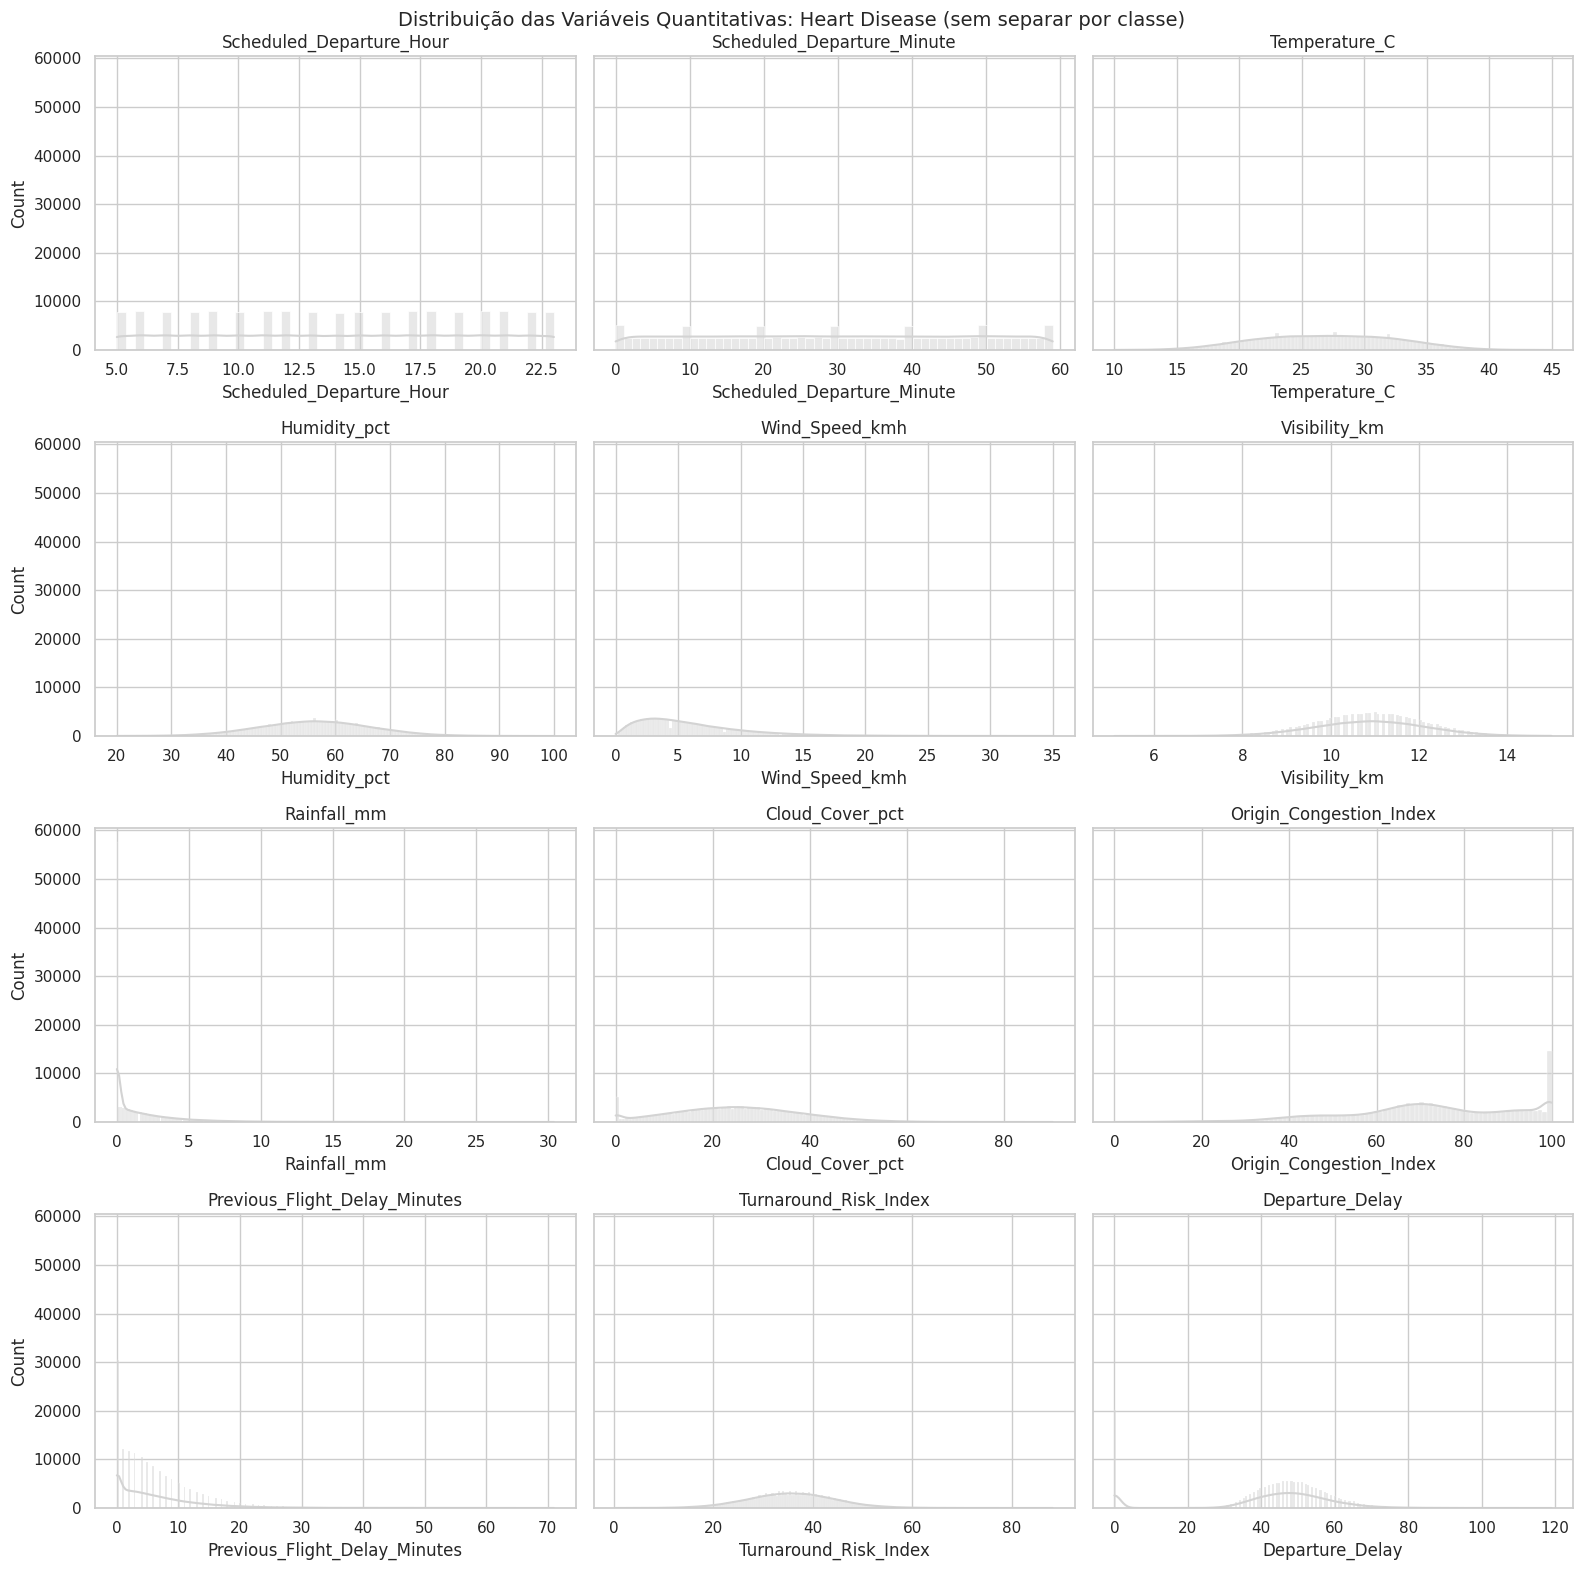

In [ ]:
import math
import matplotlib.pyplot as plt
import seaborn as sns
VARS_QUANT = [
    "Scheduled_Departure_Hour",
    "Scheduled_Departure_Minute",
    "Temperature_C",
    "Humidity_pct",
    "Wind_Speed_kmh",
    "Visibility_km",
    "Rainfall_mm",
    "Cloud_Cover_pct",
    "Origin_Congestion_Index",
    "Previous_Flight_Delay_Minutes",
    "Turnaround_Risk_Index",
    "Departure_Delay"
]
n_cols = 3
n_rows = math.ceil(len(VARS_QUANT) / n_cols)

fig, axes = plt.subplots(n_rows, n_cols, figsize=(16, 4 * n_rows), sharey=True)
axes = axes.ravel()

for i, col in enumerate(VARS_QUANT):
    sns.histplot(data=df, x=col, kde=True, color=COR_NEUTRA, ax=axes[i])
    axes[i].set_title(col)

for ax in axes[len(VARS_QUANT):]:
    ax.axis("off")

fig.suptitle("Distribuição das Variáveis Quantitativas: Heart Disease (sem separar por classe)", fontsize=14)
plt.tight_layout()
plt.show()

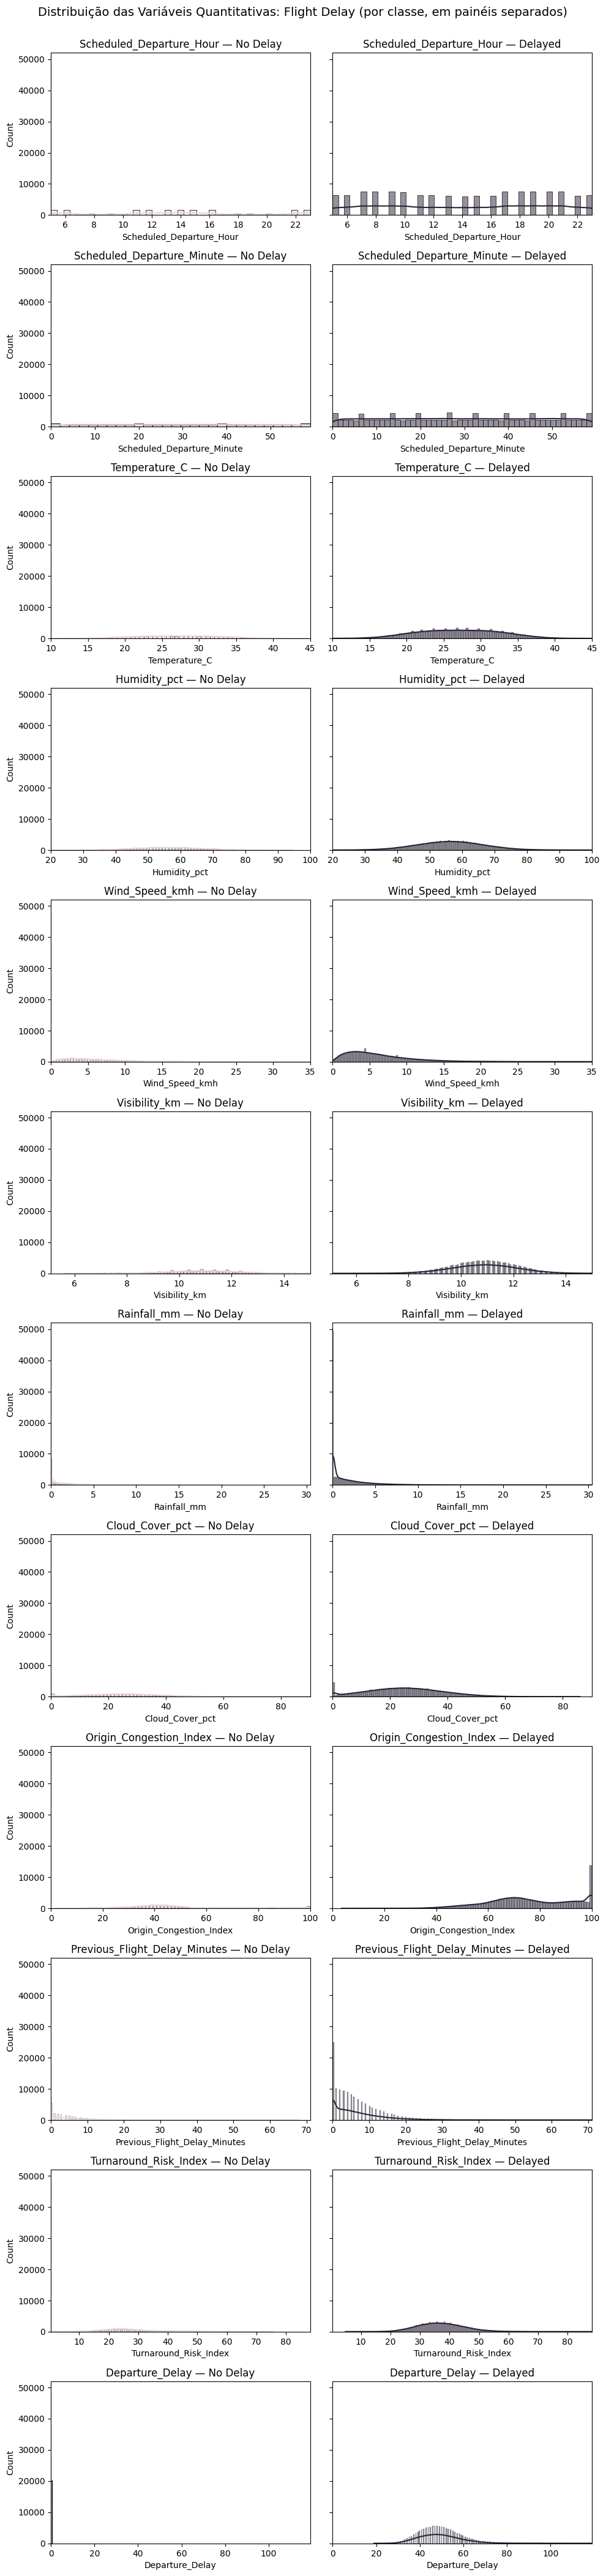

In [ ]:
fig, axes = plt.subplots(len(VARS_QUANT), 2, figsize=(10, 3.5 * len(VARS_QUANT)), sharey=True)

for i, col in enumerate(VARS_QUANT):
    lim = (df[col].min(), df[col].max())

    for j, (valor_alvo, label, cor) in enumerate([(0, "No Delay", COR_CONTEXTO), (1, "Delayed", COR_DESTAQUE)]):
        subset = df[df["Delay_Target"] == valor_alvo]
        sns.histplot(data=subset, x=col, kde=True, color=cor, ax=axes[i, j])
        axes[i, j].set_xlim(lim)
        axes[i, j].set_title(f"{col} — {label}")

fig.suptitle("Distribuição das Variáveis Quantitativas: Flight Delay (por classe, em painéis separados)", fontsize=14, y=1.001)
plt.tight_layout()
plt.show()

**Para discutir:** agora que as classes estão em painéis separados (mesma escala de eixo X em cada linha), fica mais fácil ver: alguma variável parece ter formato bem diferente entre "Delay" e "No Delay"?

Resposta:
A variável Origin_Congestion_Index na classe "No delay" a distribuicao é bem suave, quase imperceptivel, com uma pequena elecacao no centro e caindo nas pontas. Na classe "Delayed" o formato sofre uma mudanca perceptivel, apresenta um pico maior na ponta direita, de maneira a indicar um congestionamento maximo dos atrasos na origem que altera o padrão dos dados, fortemente associado aos atrasos de voo.

A váriavel Departure_Delay na classe "No Delay" o formato é apenas uma linha reta vertical no zero, já que não há atraso. Na classe "Delayed" o formato passa a ser uma curva distruibuida ao longo do eixo X, com uma maior concentracão de atrasos na faixa dos 40 a 50 minutos.



#### Testes de Aderência

*Será se o colesterol segue uma distribuição normal?*

O **Shapiro-Wilk** como o teste de aderência mais usado pra normalidade, junto com o **QQ-Plot** como visualização de apoio. Vamos testar com `chol`.

Shapiro-Wilk — Departure_Delay (Amostra): estatística=0.8370, p-valor=8.679e-58
Rejeita H0 (normalidade)? Sim (alpha = 0.05)


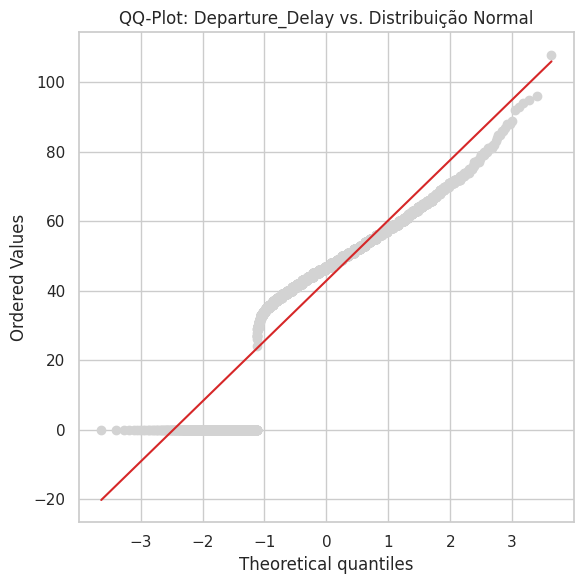

In [ ]:
amostra_delay = df["Departure_Delay"].dropna().sample(n=min(5000, len(df)), random_state=42)

stat_sw, p_valor_sw = stats.shapiro(amostra_delay)
print(f"Shapiro-Wilk — Departure_Delay (Amostra): estatística={stat_sw:.4f}, p-valor={p_valor_sw:.4g}")
print("Rejeita H0 (normalidade)?", "Sim" if p_valor_sw < 0.05 else "Não", "(alpha = 0.05)")

"""### QQ-Plot — Departure_Delay"""

fig, ax = plt.subplots(figsize=(6, 6))
stats.probplot(amostra_delay, dist="norm", plot=ax)
ax.get_lines()[0].set_markerfacecolor(COR_NEUTRA)
ax.get_lines()[0].set_markeredgecolor(COR_NEUTRA)
ax.get_lines()[1].set_color(COR_ALERTA)
ax.set_title("QQ-Plot: Departure_Delay vs. Distribuição Normal")
plt.tight_layout()
plt.show()

**Como ler:** se os pontos (roxo) seguissem a reta vermelha de perto, a variável seguiria uma normal. Pontos que se afastam da reta nas pontas indicam cauda mais pesada ou mais leve que a normal — coerente com o resultado do Shapiro-Wilk acima.

**Nota: cuidado com duas armadilhas de interpretação**

- **Tamanho da amostra e poder do teste:** é comum achar que "poucos dados" tornam mais fácil rejeitar a normalidade e é o contrário. Amostras **pequenas** têm **menos poder estatístico**, ou seja, tendem a *não* rejeitar mesmo quando os dados realmente não são normais. Já amostras **muito grandes** (milhares de linhas) deixam o teste sensível demais, rejeitando por desvios triviais. Com n≈303 (nem pequeno, nem enorme) e três evidências concordando — skewness alto, QQ-Plot afastado da reta, e Shapiro-Wilk rejeitando — o resultado é razoavelmente confiável, não um artefato do tamanho da amostra.
- **Como afirmar o resultado:** quando o teste **rejeita** H0 (nosso caso, p < 0.05), a afirmação correta é "temos evidência estatística **contra** a normalidade" que é uma conclusão forte. A frase "não podemos garantir normalidade" cabe no caso oposto: quando o teste **não rejeita** H0, já que a ausência de rejeição nunca prova que os dados são normais, só que não há evidência suficiente contra.

In [ ]:
resultados_shapiro = []
for col in VARS_QUANT:
    amostra = df[col].dropna()
    if len(amostra) > 5000:
        amostra = amostra.sample(n=5000, random_state=42)

    stat, p = stats.shapiro(amostra)
    resultados_shapiro.append({"variavel": col, "estatistica": round(stat, 4),
                                "p_valor": round(p, 6), "rejeita_normalidade": p < 0.05})

pd.DataFrame(resultados_shapiro).set_index("variavel")

,estatistica,p_valor,rejeita_normalidade
variavel,,,
Scheduled_Departure_Hour,0.9489,0.000000,True
Scheduled_Departure_Minute,0.9563,0.000000,True
Temperature_C,0.9940,0.000000,True
Humidity_pct,0.9996,0.405116,False
Wind_Speed_kmh,0.9028,0.000000,True
Visibility_km,0.9990,0.003736,True
Rainfall_mm,0.7195,0.000000,True
Cloud_Cover_pct,0.9911,0.000000,True
Origin_Congestion_Index,0.9624,0.000000,True


**ECDF — outra forma de ver a distribuição**

Diferente do histograma, a ECDF não depende de escolher o número de bins: para cada valor no eixo X, a curva mostra a **proporção acumulada** de observações menores ou iguais àquele valor. É especialmente útil pra comparar duas distribuições lado a lado — onde as curvas se distanciam mais é onde a diferença entre os grupos é mais perceptível.

Vamos ilustrar com uma única variável (`chol`, colesterol), só pra fixar como essa visualização se lê.

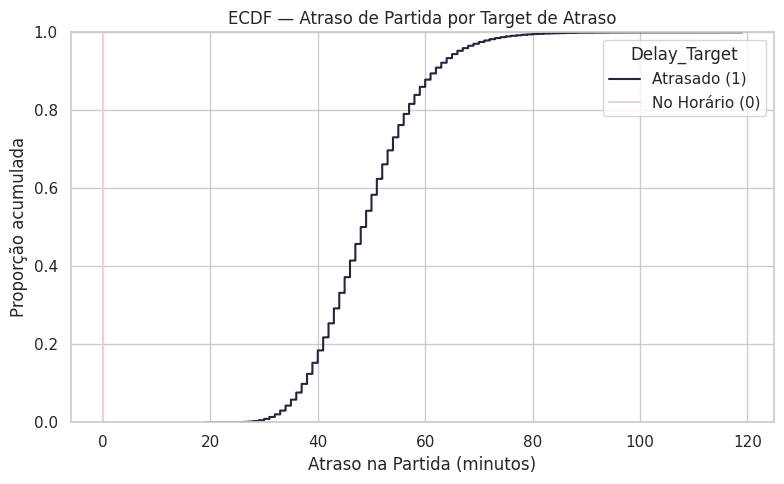

In [ ]:
plt.figure(figsize=(8, 5))
sns.ecdfplot(data=df, x="Departure_Delay", hue="Delay_Target",
             palette={0: COR_CONTEXTO, 1: COR_DESTAQUE})
plt.title("ECDF — Atraso de Partida por Target de Atraso")
plt.xlabel("Atraso na Partida (minutos)")
plt.ylabel("Proporção acumulada")
plt.legend(title="Delay_Target", labels=["Atrasado (1)", "No Horário (0)"])
plt.tight_layout()
plt.show()

**Como ler:** em qualquer ponto do eixo X, a altura da curva diz "que fração dos pacientes desse grupo tem colesterol até aqui". Onde as duas curvas (rosa e roxa) se distanciam mais, ali está a faixa de colesterol onde os dois grupos mais diferem, sem precisar decidir uma largura de bin como no histograma.

### Métricas de Tendêncial Central

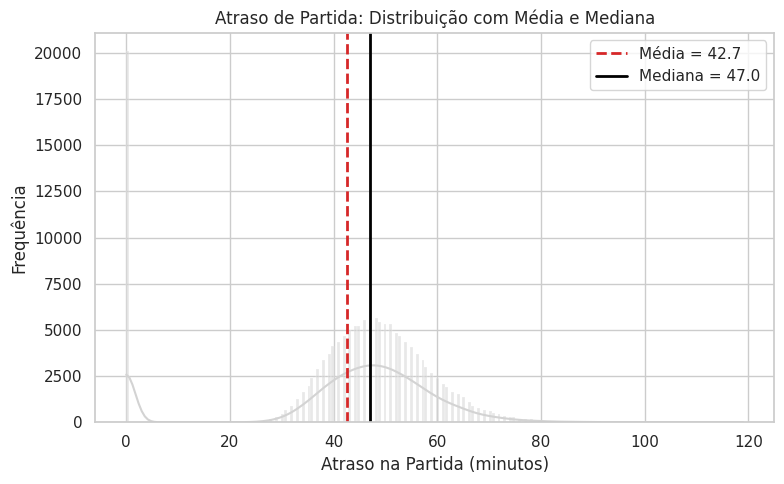

In [ ]:
media_delay = df["Departure_Delay"].mean()
mediana_delay = df["Departure_Delay"].median()

plt.figure(figsize=(8, 5))
sns.histplot(data=df, x="Departure_Delay", kde=True, color=COR_NEUTRA)
plt.axvline(media_delay, color=COR_ALERTA, linestyle="--", linewidth=2, label=f"Média = {media_delay:.1f}")
plt.axvline(mediana_delay, color="black", linestyle="-", linewidth=2, label=f"Mediana = {mediana_delay:.1f}")
plt.title("Atraso de Partida: Distribuição com Média e Mediana")
plt.xlabel("Atraso na Partida (minutos)")
plt.ylabel("Frequência")
plt.legend()
plt.tight_layout()
plt.show()

### Dispersão

                                  var    std   IQR
Scheduled_Departure_Hour        30.03   5.48  10.0
Scheduled_Departure_Minute     300.05  17.32  30.0
Temperature_C                   30.13   5.49   8.2
Humidity_pct                   103.26  10.16  13.7
Wind_Speed_kmh                  17.84   4.22   5.2
Visibility_km                    1.62   1.27   1.7
Rainfall_mm                      5.81   2.41   2.5
Cloud_Cover_pct                169.53  13.02  18.0
Origin_Congestion_Index        371.63  19.28  27.9
Previous_Flight_Delay_Minutes   42.04   6.48   8.0
Turnaround_Risk_Index           76.03   8.72  11.6
Departure_Delay                361.64  19.02  15.0


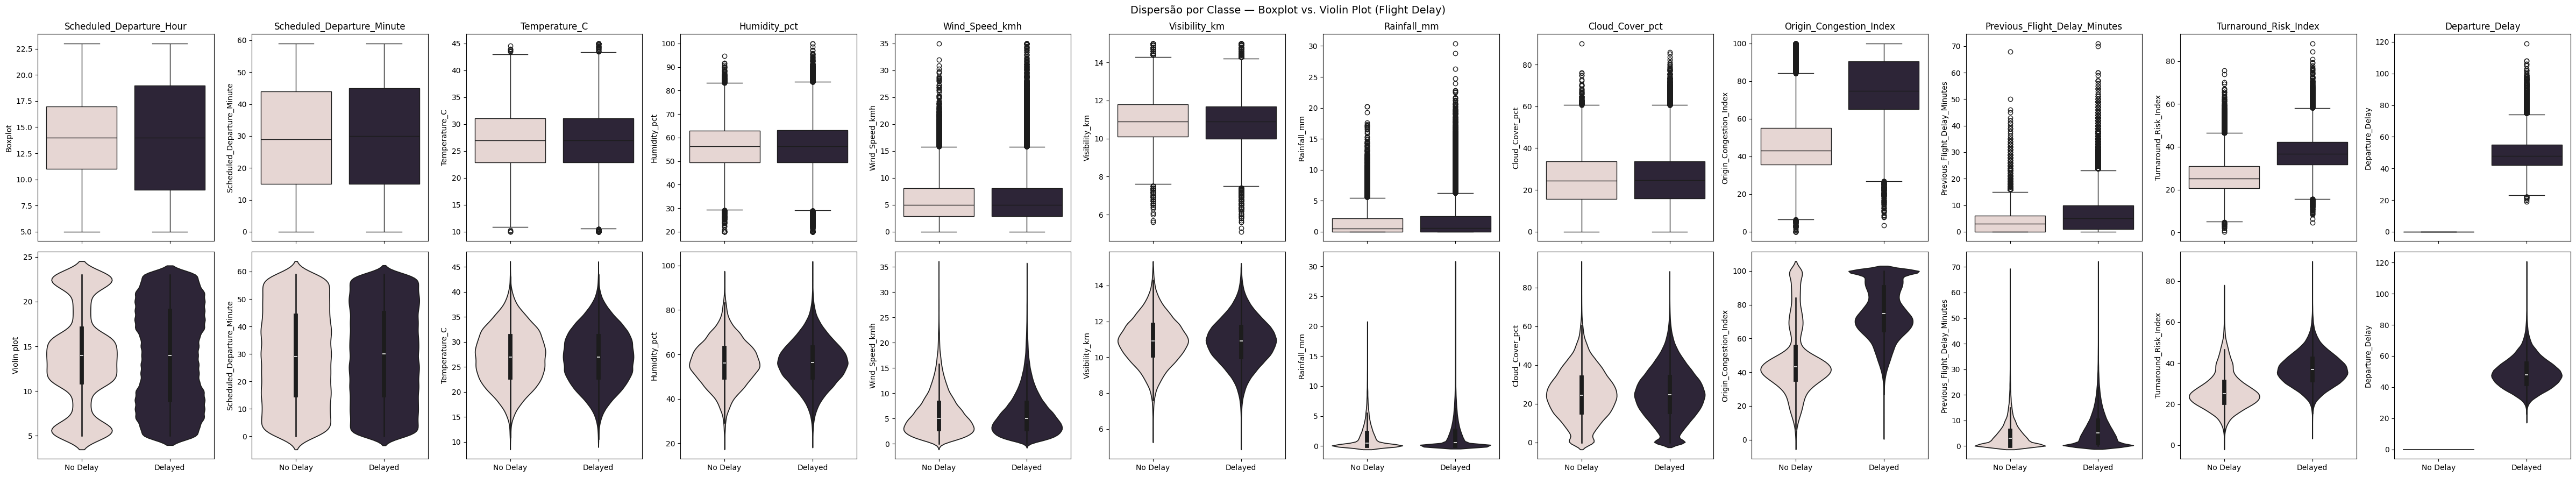

In [ ]:
dispersao = df[VARS_QUANT].agg(["var", "std"]).T
dispersao["IQR"] = df[VARS_QUANT].quantile(0.75) - df[VARS_QUANT].quantile(0.25)
print(dispersao.round(2))

"""### Boxplot e violin plot por classe"""

palette_classe = {0: COR_CONTEXTO, 1: COR_DESTAQUE}

fig, axes = plt.subplots(2, len(VARS_QUANT), figsize=(4 * len(VARS_QUANT), 9), sharex="col")

for i, col in enumerate(VARS_QUANT):
    sns.boxplot(data=df, x="Delay_Target", y=col, hue="Delay_Target",
                palette=palette_classe, legend=False, ax=axes[0, i])
    axes[0, i].set_title(col)
    axes[0, i].set_xlabel("")
    axes[0, i].set_xticks([0, 1])
    axes[0, i].set_xticklabels(["No Delay", "Delayed"])

    sns.violinplot(data=df, x="Delay_Target", y=col, hue="Delay_Target",
                    palette=palette_classe, legend=False, ax=axes[1, i])
    axes[1, i].set_xlabel("")
    axes[1, i].set_xticks([0, 1])
    axes[1, i].set_xticklabels(["No Delay", "Delayed"])

axes[0, 0].set_ylabel("Boxplot")
axes[1, 0].set_ylabel("Violin plot")
fig.suptitle("Dispersão por Classe — Boxplot vs. Violin Plot (Flight Delay)", fontsize=14)
plt.tight_layout()
plt.show()

**Pra discutir:** alguma variável mostra uma caixa (IQR) nitidamente mais alta ou mais baixa entre "No delay" e "Delayed"? Isso já é um indício — antes mesmo da análise bivariada formal — de que essa variável pode ajudar a diferenciar as duas classes.

Resposta:
As variáveis Origin_Congestion_Index, Turnaround_Risk_Index e Departure_Delay são varíaveis que expressam um IQR extremo.

Em Origin_Congestion_Index, delayed está bem deslocada para o alto em relacao a classe no delay. O gráfico em formato de violino reforca esse indicio pela demonstracao da grande concentracao dos dados proximos ao valor maximo. Isso acontece pois a congestão na partida é um dos principais indicadores para o atraso, de acordo com o apresentado no dataset.

Em Turnaround_Risk_Index, a caixa da classe delayed está posicionada em um patamar superior. A variavel apresentada influencia para que atrasos ocorram, como consta o dataset, risco de turnaround acima influencia diretamente para que atrasos de voo acontecam.

Em Departure_Delay, é a variacel que quantifica o atraso, por isso a classe No Delay esát bem proxima ao zero, enquanto a delayed está bem posicionada acima.

## 4. Tratamento de Dados Ausentes e Outliers

Agora que já vimos o retrato estatístico "antes" (Seção 3), temos a informação que faltava pra decidir como tratar tanto os dados ausentes (`ca`, `thal`) quanto os outliers das variáveis quantitativas. Depois do tratamento, vamos rodar a estatística descritiva mais uma vez ("depois") pra confirmar o efeito das escolhas e fechar o ciclo iterativo que começamos lá na abertura.

### Detecção de Outliers por IQR

A regra clássica marca como outlier qualquer ponto fora de `[Q1 - 1.5*IQR, Q3 + 1.5*IQR]`.

In [ ]:
import pandas as pd
import numpy as np

try:
    df
except NameError:
    if 'variavel' in globals():
        df = pd.read_csv(variavel)
    else:
        import kagglehub
        import os
        path = kagglehub.dataset_download("leofire123/indian-flight-delay-datasets")
        variavel = os.path.join(path, 'india_flight_delay_model_input.csv')
        df = pd.read_csv(variavel)

VARS_QUANT = [
    "Scheduled_Departure_Hour",
    "Scheduled_Departure_Minute",
    "Temperature_C",
    "Humidity_pct",
    "Wind_Speed_kmh",
    "Visibility_km",
    "Rainfall_mm",
    "Cloud_Cover_pct",
    "Origin_Congestion_Index",
    "Previous_Flight_Delay_Minutes",
    "Turnaround_Risk_Index",
    "Departure_Delay"
]

def limites_iqr(serie):
    q1, q3 = serie.quantile([0.25, 0.75])
    iqr = q3 - q1
    return q1 - 1.5 * iqr, q3 + 1.5 * iqr

resumo_outliers = {}
for col in VARS_QUANT:
    if col in df.columns:
        lim_inf, lim_sup = limites_iqr(df[col])
        n_outliers = ((df[col] < lim_inf) | (df[col] > lim_sup)).sum()
        resumo_outliers[col] = {
            "limite_inferior": round(lim_inf, 2),
            "limite_superior": round(lim_sup, 2),
            "n_outliers": n_outliers,
        }

pd.DataFrame(resumo_outliers).T

Using Colab cache for faster access to the 'indian-flight-delay-datasets' dataset.


,limite_inferior,limite_superior,n_outliers
Scheduled_Departure_Hour,-6.00,34.00,0.0
Scheduled_Departure_Minute,-30.00,90.00,0.0
Temperature_C,10.60,43.40,76.0
Humidity_pct,28.95,83.75,1038.0
Wind_Speed_kmh,-4.90,15.90,4666.0
Visibility_km,7.45,14.25,1163.0
Rainfall_mm,-3.75,6.25,8692.0
Cloud_Cover_pct,-11.20,60.80,633.0
Origin_Congestion_Index,19.05,130.65,969.0
Previous_Flight_Delay_Minutes,-11.00,21.00,4873.0


### Visualizando os Outliers

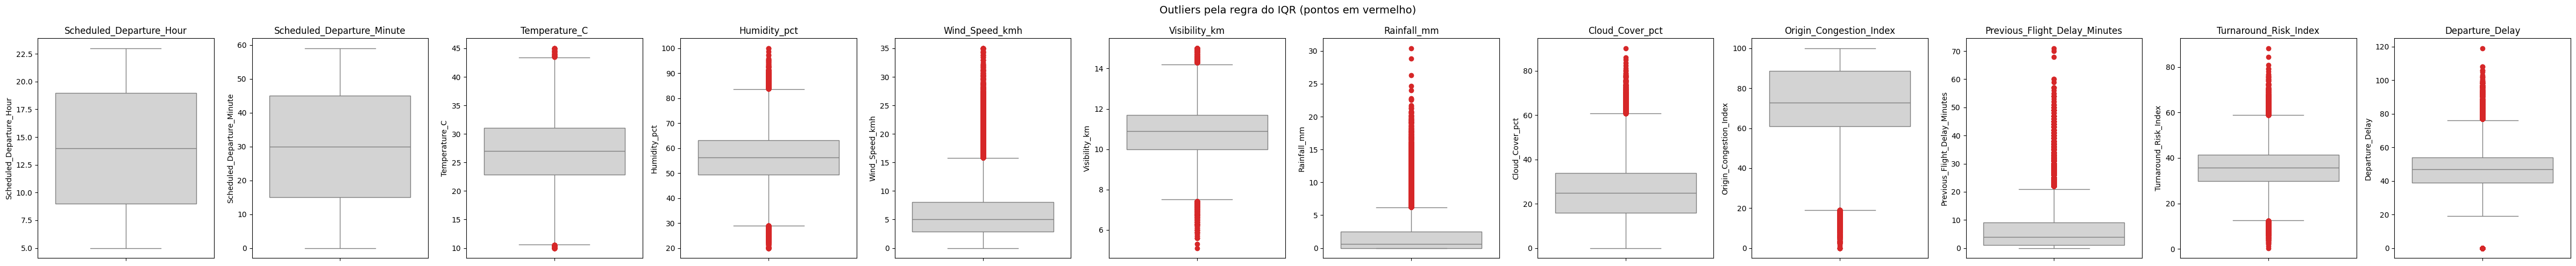

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

COR_NEUTRA = "lightgray"
COR_ALERTA = "tab:red"

fig, axes = plt.subplots(1, len(VARS_QUANT), figsize=(4 * len(VARS_QUANT), 5))

for i, col in enumerate(VARS_QUANT):
    sns.boxplot(data=df, y=col, color=COR_NEUTRA,
                flierprops=dict(markerfacecolor=COR_ALERTA, markeredgecolor=COR_ALERTA, marker="o"),
                ax=axes[i])
    axes[i].set_title(col)

fig.suptitle("Outliers pela regra do IQR (pontos em vermelho)", fontsize=14)
plt.tight_layout()
plt.show()

**Pra discutir:** o slide 26 da aula 9 classifica outliers em três tipos, cada um com um tratamento recomendado:

| Tipo | Cenário | O que fazer? |
|---|---|---|
| Estatístico | Legítimo | Manter / Transformar |
| De domínio | Viola regra de negócio ou condições físicas | Investigar! |
| Erros de dados | Falhas | Corrigir se possível / Remover como última opção |

Olhando os outliers encontrados (principalmente em Rainfall_mm e Departure_Delay), eles parecem meteorológica ou operacionalmente plausíveis (dias reais podem ter tempestades extremas e voos podem sofrer atrasos severos em cascata), ou parecem violar algum limite físico/lógico conhecido? Isso muda qual das três categorias da tabela se aplica — e, consequentemente, se devemos manter, transformar ou remover."

Resposta:
Esses outliers são totalmente plausíveis do ponto de vista meteorológico e operacional, não violando nenhum limite físico ou lógico, como valores de chuva negativos ou minutos de voo absurdos. Na prática, eles representam cenários reais e críticos do dia a dia da aviação. Analisando a variável de precipitação (Rainfall_mm), por exemplo, os valores extremos na cauda da distribuição, na casa dos 20 a 30 milímetros, representam chuvas fortes e tempestades severas. Embora sejam eventos mais raros no quadro geral, eles são perfeitamente possíveis na natureza e costumam ser exatamente os maiores causadores de interrupções nas operações aeroportuárias. Da mesma forma, os atrasos na partida (Departure_Delay) de 100 ou 120 minutos refletem situações atípicas, mas muito conhecidas no setor, como fechamentos temporários de pistas, falhas mecânicas ou o temido efeito cascata na malha aérea.

### Decidindo o Tratamento dos Dados Ausentes

Reunindo o que já discutimos: o mecanismo mais provável para `ca`/`thal` é MAR ou MCAR (não MNAR), e o volume é pequeno (poucas linhas em ~300). Com essas duas informações juntas, a decisão pragmática é remover as linhas afetadas — o risco de viés é baixo (mecanismo provavelmente não depende do próprio valor ausente) e o custo de perder ~2% das linhas é pequeno.

In [ ]:
linhas_antes = df.shape[0]
df_antes = df.copy()

df = df.dropna().reset_index(drop=True)
linhas_depois = df.shape[0]

print(f"Linhas antes: {linhas_antes} | Linhas depois: {linhas_depois} | Removidas: {linhas_antes - linhas_depois}")

Linhas antes: 150000 | Linhas depois: 150000 | Removidas: 0


### Decidindo o Tratamento dos Outliers

Diferente dos ausentes, aqui **não vamos remover automaticamente**. Pelos valores encontrados (dentro de faixas clinicamente plausíveis, ainda que raras), a classificação mais provável é **"Estatístico"**, outliers legítimos, não erros de coleta. Sendo assim, o tratamento recomendado nesse caso é **manter** (a informação é real e pode ser clinicamente relevante — por exemplo, exatamente os pacientes com colesterol mais extremo podem ser os de maior risco) ou, se for necessário para alguma técnica estatística específica mais à frente (ex: métodos sensíveis à assimetria), **transformar**.

Vamos manter os valores originais por enquanto, mas ilustrar como ficaria uma transformação logarítmica em `chol` — útil caso, mais adiante em análises futuras, a assimetria atrapalhe algum teste ou modelo.

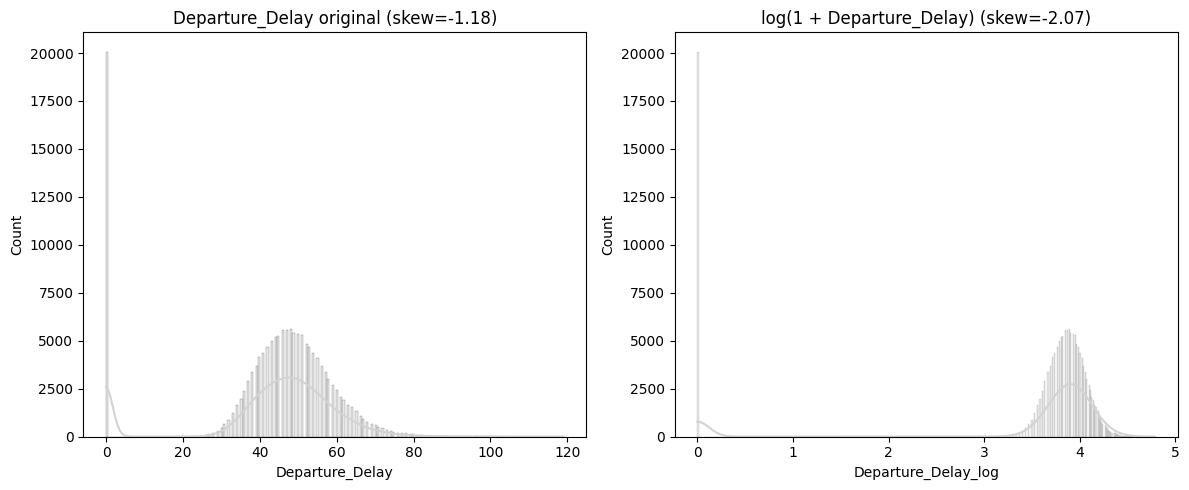

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

if "Departure_Delay" in df.columns:
    df["Departure_Delay_log"] = np.log1p(df["Departure_Delay"])

    fig, axes = plt.subplots(1, 2, figsize=(12, 5))
    sns.histplot(data=df, x="Departure_Delay", kde=True, color=COR_NEUTRA, ax=axes[0])
    axes[0].set_title(f"Departure_Delay original (skew={df['Departure_Delay'].skew():.2f})")

    sns.histplot(data=df, x="Departure_Delay_log", kde=True, color=COR_NEUTRA, ax=axes[1])
    axes[1].set_title(f"log(1 + Departure_Delay) (skew={df['Departure_Delay_log'].skew():.2f})")

    plt.tight_layout()
    plt.show()
else:
    print("Coluna 'Departure_Delay' não encontrada no DataFrame.")

**Pra discutir:** a transformação logarítmica reduziu visivelmente a assimetria? Mantivemos `Departure_Delay_log` só como demonstração, mas não vamos usá-la nas próximas seções. A ideia foi mostrar como opção se fosse o objetivo de, por exemplo, alimentar um teste paramétrico que exige normalidade.

**Nota para quando vocês replicarem no dataset de vocês:** nem todo outlier deve ser removido. Antes de decidir, classifiquem: é um valor estatisticamente raro mas plausível (manter/transformar), viola alguma regra física ou de negócio (investigar antes de decidir), ou é claramente um erro de digitação/coleta (corrigir ou remover)?

Resposta:
não, a transformação logarítmica, na verdade, piorou a assimetria da variável. Olhando para os gráficos e os números, a métrica de assimetria (skew) passou de -1.18 no gráfico original para -2.07 na versão transformada, afastando-se ainda mais de zero, que seria o indicativo de uma distribuição normal e simétrica. O problema central aqui é que a variável de atrasos possui o que chamamos de dados inflados de zeros, ou seja, um pico massivo e absoluto concentrado exatamente no zero, representando os voos pontuais.


## 5. Estatística Descritiva pt 2

Fechando o ciclo iterativo: tratamos os ausentes e decidimos manter os outliers. Agora rodamos a mesma bateria de estatísticas da Seção 3 para comparar diretamente com o "antes".

In [ ]:
import pandas as pd

desc_depois = df[VARS_QUANT].describe().T
desc_depois["skewness"] = df[VARS_QUANT].skew()
desc_depois["kurtosis"] = df[VARS_QUANT].kurtosis()

desc_depois = desc_depois.rename(columns={"50%": "median"})

(
    desc_depois[["mean", "median", "std", "min", "max", "skewness", "kurtosis"]]
    .round(2)
    .style.format(precision=2)
    .background_gradient(cmap="Blues", subset=["skewness", "kurtosis"])
)

,mean,median,std,min,max,skewness,kurtosis
Scheduled_Departure_Hour,14.00,14.00,5.48,5.00,23.00,-0.00,-1.21
Scheduled_Departure_Minute,29.53,30.00,17.32,0.00,59.00,-0.00,-1.20
Temperature_C,27.03,27.00,5.49,10.00,45.00,-0.01,-0.54
Humidity_pct,56.33,56.30,10.16,20.00,100.00,0.01,-0.02
Wind_Speed_kmh,5.99,5.00,4.22,0.00,35.00,1.38,2.78
Visibility_km,10.89,10.90,1.27,5.10,15.00,-0.04,0.01
Rainfall_mm,1.67,0.60,2.41,0.00,30.40,2.24,6.84
Cloud_Cover_pct,25.01,24.80,13.02,0.00,90.10,0.20,-0.22
Origin_Congestion_Index,72.41,72.70,19.28,0.00,100.00,-0.45,-0.30
Previous_Flight_Delay_Minutes,6.17,4.00,6.48,0.00,71.00,1.64,3.81


### Comparando "antes"x "depois""



In [ ]:
import pandas as pd

desc = df_antes[VARS_QUANT].describe().T
desc["skewness"] = df_antes[VARS_QUANT].skew()
desc["kurtosis"] = df_antes[VARS_QUANT].kurtosis()

comparacao = pd.DataFrame({
    "skewness_antes": desc["skewness"],
    "skewness_depois": desc_depois["skewness"],
    "kurtosis_antes": desc["kurtosis"],
    "kurtosis_depois": desc_depois["kurtosis"],
})

comparacao["delta_skewness"] = (comparacao["skewness_depois"] - comparacao["skewness_antes"]).round(3)
comparacao["delta_kurtosis"] = (comparacao["kurtosis_depois"] - comparacao["kurtosis_antes"]).round(3)

comparacao.round(3)

,skewness_antes,skewness_depois,kurtosis_antes,kurtosis_depois,delta_skewness,delta_kurtosis
Scheduled_Departure_Hour,-0.001,-0.001,-1.210,-1.210,0.0,0.0
Scheduled_Departure_Minute,-0.001,-0.001,-1.198,-1.198,0.0,0.0
Temperature_C,-0.006,-0.006,-0.541,-0.541,0.0,0.0
Humidity_pct,0.011,0.011,-0.021,-0.021,0.0,0.0
Wind_Speed_kmh,1.384,1.384,2.777,2.777,0.0,0.0
Visibility_km,-0.042,-0.042,0.013,0.013,0.0,0.0
Rainfall_mm,2.240,2.240,6.844,6.844,0.0,0.0
Cloud_Cover_pct,0.201,0.201,-0.218,-0.218,0.0,0.0
Origin_Congestion_Index,-0.450,-0.450,-0.300,-0.300,0.0,0.0
Previous_Flight_Delay_Minutes,1.636,1.636,3.810,3.810,0.0,0.0


**Pra discutir:** os valores mudaram muito? Fazia sentido esperar uma diferença grande, considerando que removemos só ~2% das linhas e decidimos **não** alterar nenhum outlier? Esse resultado (pouca mudança) é, na verdade, uma confirmação de que o tratamento foi conservador — não um sinal de que ele não fez nada de útil.

Resposta:
Não, os valores não mudaram absolutamente nada, como as colunas de variação indicam com o valor zero para todas as variáveis analisadas. Primeiro, a assimetria e a curtose são medidas estatísticas altamente sensíveis a valores extremos, manter os outliers intactos para preservar fenômenos legítimos da operação aérea, as caudas que puxam o cálculo dessas métricas continuaram exatamente no mesmo lugar. Segundo, remover apenas cerca de dois por cento das linhas de um banco de dados volumoso é uma intervenção mínima, provavelmente correspondendo a sujeiras técnicas como valores nulos ou inconsistências sistêmicas, o que não tem força matemática para deslocar o centro de massa ou a dispersão geral

**O colesterol ainda rejeita normalidade?**

Vamos rodar o mesmo Shapiro-Wilk da Seção 3, agora nos dados tratados.

In [ ]:
from scipy import stats

amostra_antes = df_antes["Departure_Delay"].dropna().sample(n=5000, random_state=42)
amostra_depois = df["Departure_Delay"].dropna().sample(n=5000, random_state=42)

stat_sw_antes, p_valor_sw_antes = stats.shapiro(amostra_antes)
stat_sw_depois, p_valor_sw_depois = stats.shapiro(amostra_depois)

print(f"Shapiro-Wilk (antes)  — Departure_Delay: estatística={stat_sw_antes:.4f}, p-valor={p_valor_sw_antes:.4g}")
print(f"Shapiro-Wilk (depois) — Departure_Delay: estatística={stat_sw_depois:.4f}, p-valor={p_valor_sw_depois:.4g}")

Shapiro-Wilk (antes)  — Departure_Delay: estatística=0.8370, p-valor=8.679e-58
Shapiro-Wilk (depois) — Departure_Delay: estatística=0.8370, p-valor=8.679e-58


**Visualizando antes x depois, lado a lado**

Vamos sobrepor as distribuições de duas variáveis que mais chamaram atenção na Seção 4 (`chol` e `oldpeak`), comparando a versão original (`df_antes`) com a tratada (`df`).

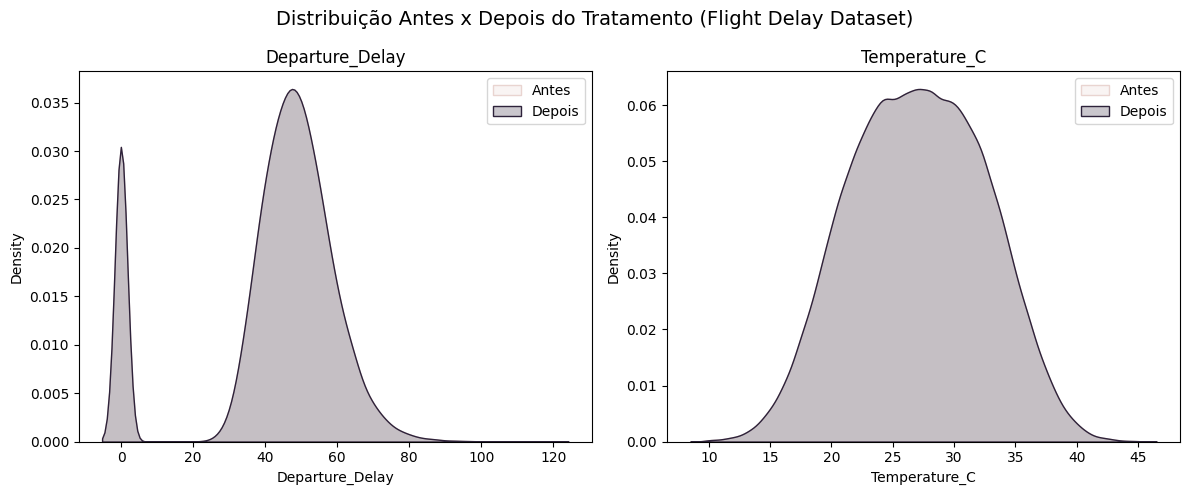

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

COR_CONTEXTO = "#e9d4d0"
COR_DESTAQUE = "#2d223a"

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

for ax, col in zip(axes, ["Departure_Delay", "Temperature_C"]):
    sns.kdeplot(data=df_antes, x=col, color=COR_CONTEXTO, fill=True, label="Antes", ax=ax)
    sns.kdeplot(data=df, x=col, color=COR_DESTAQUE, fill=True, label="Depois", ax=ax)
    ax.set_title(col)
    ax.legend()

fig.suptitle("Distribuição Antes x Depois do Tratamento (Flight Delay Dataset)", fontsize=14)
plt.tight_layout()
plt.show()

**Pra discutir:** as curvas "antes" e "depois" praticamente se sobrepõem? Isso é o esperado aqui, já que removemos poucas linhas e não tocamos nos outliers.

Resposta:
Sim, as curvas de antes e depois se sobrepõem perfeitamente em ambos os gráficos da imagem, a ponto de parecerem uma única distribuição. Essa sobreposição total é exatamente o comportamento esperado e confirma de forma visual o que os números já indicavam: a limpeza foi extremamente conservadora e cirúrgica. Como a intervenção no dataset removeu apenas uma quantidade mínima de linhas corrompidas e manteve todos os outliers inalterados, a estrutura original dos dados não sofreu nenhum impacto estatístico. Ao preservar todos os eventos extremos legítimos, como os grandes tempos de espera no "Departure_Delay" e as variações climáticas na temperatura, o centro de massa, a dispersão e as caudas das variáveis permaneceram idênticos. O fato de não haver nenhum deslocamento perceptível entre as áreas desenhadas é a prova definitiva de que o pré-processamento não introduziu distorções ou vieses artificiais, garantindo que o seu futuro modelo aprenda com o retrato fiel e inalterado da realidade da malha aérea.

Guardem essa observação: em datasets onde o volume de ausentes/outliers for maior, essa mesma comparação pode mostrar uma diferença bem mais visível e sempre que essa checagem "antes x depois" que confirma (ou não) que o tratamento teve o efeito esperado, em vez de assumir isso às cegas.

## 6. Princípio Relacional

### Análise de Variáveis Qualitativas

Agora focaremos na avaliação de frequência e desbalanceamento das variáveis qualitativas.




#### Frequências absolutas e relativas

In [ ]:
VARS_QUALI = [
    "Airline",
    "Origin_Airport",
    "Destination_Airport",
    "Day_of_Week",
    "Month",
    "Is_Weekend",
    "Peak_Hour",
    "Weather"
]

for col in VARS_QUALI:
    if col in df.columns:
        freq_abs = df[col].value_counts()
        freq_rel = df[col].value_counts(normalize=True).round(3)
        print(f"\n--- {col} ---")
        print(pd.concat([freq_abs.rename("absoluta"), freq_rel.rename("relativa")], axis=1))
    else:
        print(f"\nColuna {col} não encontrada no DataFrame.")


--- Airline ---
                   absoluta  relativa
Airline                              
IndiGo                60242     0.402
Air India             26875     0.179
Air India Express     15212     0.101
Akasa Air             11937     0.080
SpiceJet              11739     0.078
Vistara                8994     0.060
Star Air               6072     0.040
Alliance Air           5915     0.039
Fly91                  3014     0.020

--- Origin_Airport ---
                absoluta  relativa
Origin_Airport                    
DEL                26337     0.176
BOM                20363     0.136
BLR                17398     0.116
HYD                14461     0.096
MAA                13019     0.087
...                  ...       ...
AGR                  326     0.002
IXA                  326     0.002
SHL                  325     0.002
NAG                  325     0.002
KNU                  309     0.002

[86 rows x 2 columns]

--- Destination_Airport ---
                     absoluta  rel

#### Visualizando as frequências

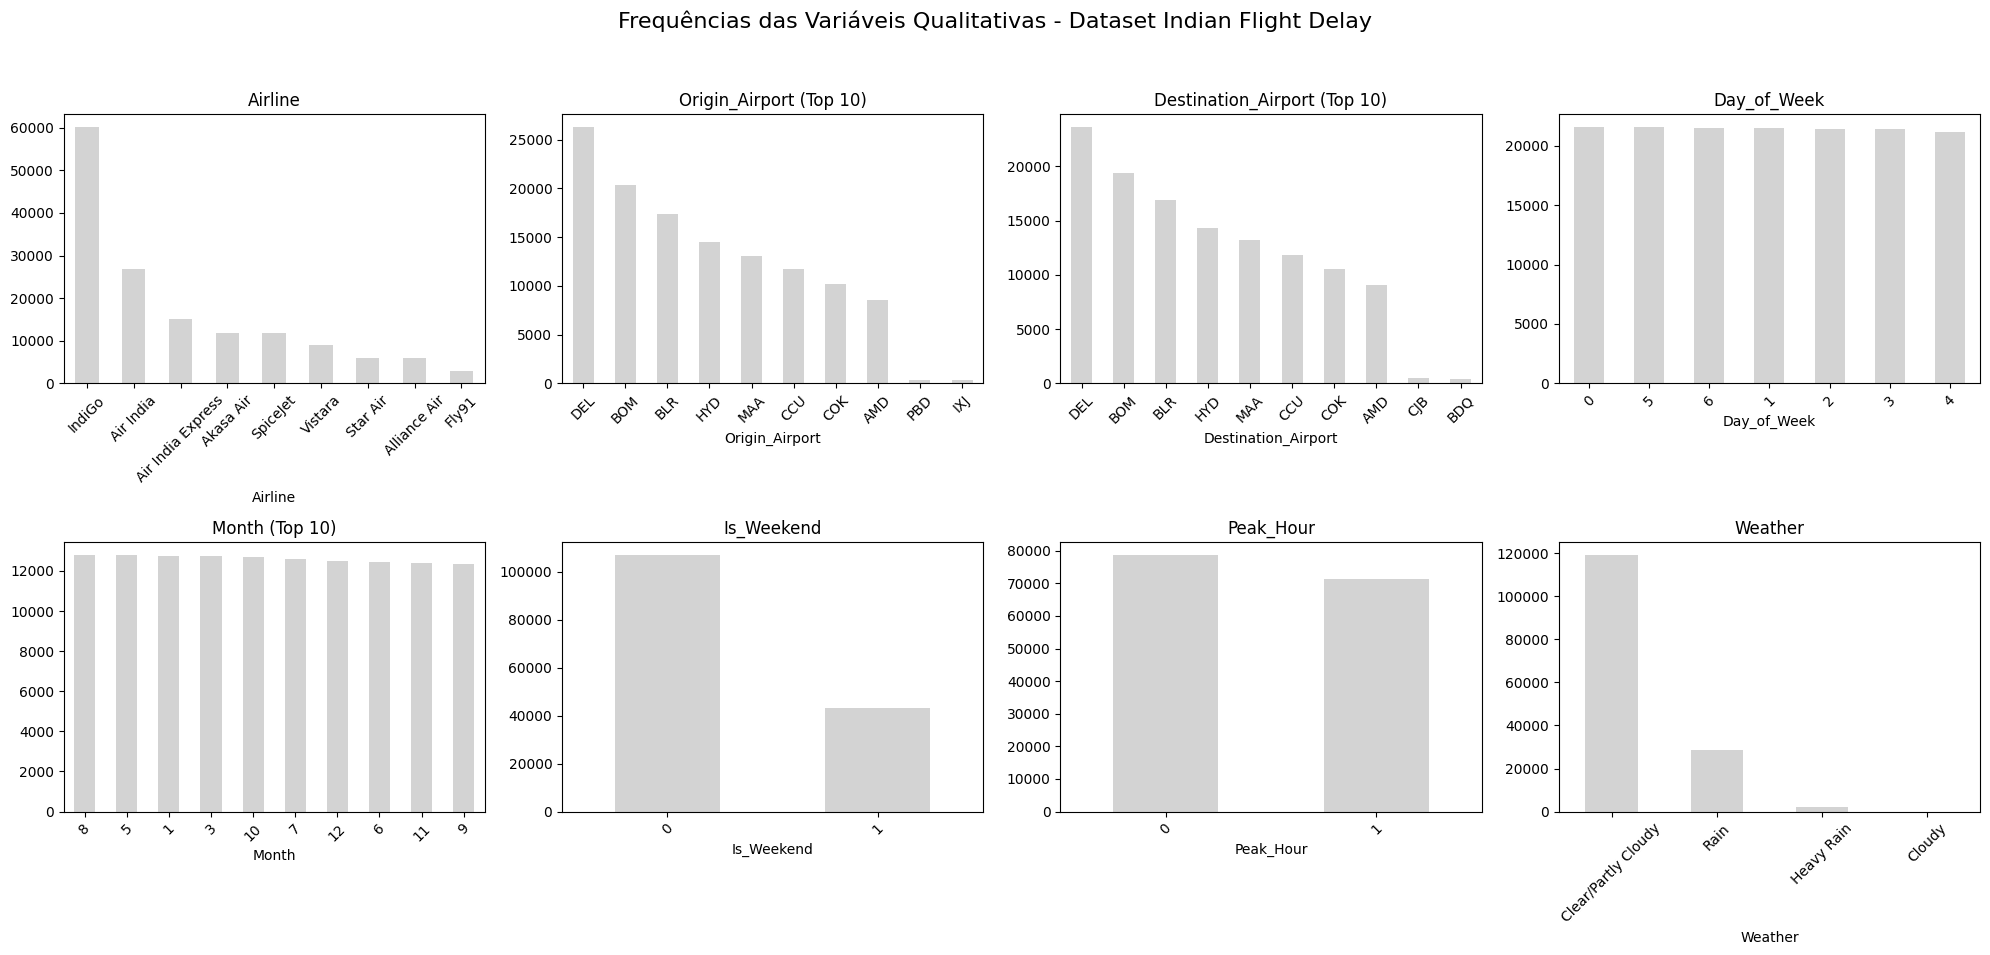

In [ ]:
import matplotlib.pyplot as plt

C_NEUTRA = globals().get('COR_NEUTRA', 'lightgray')

fig, axes = plt.subplots(2, 4, figsize=(20, 10))
axes = axes.ravel()

for i, col in enumerate(VARS_QUALI):
    if col in df.columns:

        data_plot = df[col].value_counts().head(10)

        data_plot.plot(kind="bar", color=C_NEUTRA, ax=axes[i])
        axes[i].set_title(f"{col} (Top 10)" if len(df[col].unique()) > 10 else col)
        axes[i].tick_params(axis="x", rotation=45)
    else:
        axes[i].set_title(f"{col} (Não Encontrado)")
        axes[i].axis('off')

fig.suptitle("Frequências das Variáveis Qualitativas - Dataset Indian Flight Delay", fontsize=16)
plt.tight_layout(rect=[0, 0.03, 1, 0.95])
plt.show()

**Pra discutir:** alguma variável qualitativa está bem desbalanceada (uma categoria dominando quase todas as observações)? Isso pode impactar como vamos interpretar cruzamentos com essa variável mais na frente na análise bivariada.

Resposta:
Sim, a variável Weather apresenta um desbalanceamento extremo, com a categoria "Clear/Partly Cloudy" dominando quase todas as observações, enquanto "Heavy Rain" e "Cloudy" possuem contagens praticamente invisíveis no gráfico. Outra variável com forte concentração é Airline, onde a IndiGo tem mais que o dobro de voos da segunda colocada.

#### Desbalanceamento entre Classes

- **Razão de desbalanceamento** — # classe majoritária / # classe minoritária (quanto maior, mais desbalanceado).
- **Entropia de Shannon normalizada** — 1 = perfeitamente balanceado, 0 = uma classe domina tudo.

Vamos aplicar as duas em todas as qualitativas, incluindo o próprio alvo `doenca_cardiaca`.

In [ ]:
from scipy.stats import entropy
import numpy as np
import pandas as pd

def metrica_desbalanceamento(serie):
    contagens = serie.value_counts()
    if contagens.empty:
        return pd.Series({"n_classes": 0, "razao_desbalanceamento": np.nan, "entropia_normalizada": np.nan})

    razao = contagens.max() / contagens.min()
    props = contagens / contagens.sum()
    n_classes = len(contagens)
    ent_normalizada = entropy(props, base=2) / np.log2(n_classes) if n_classes > 1 else np.nan
    return pd.Series({
        "n_classes": n_classes,
        "razao_desbalanceamento": round(razao, 2),
        "entropia_normalizada": round(ent_normalizada, 3),
    })

target_col = "Delay_Target"
vars_para_checar = [v for v in VARS_QUALI if v in df.columns]

if target_col in df.columns:
    vars_para_checar.append(target_col)

resumo_balanco = pd.DataFrame({col: metrica_desbalanceamento(df[col]) for col in vars_para_checar}).T
resumo_balanco

,n_classes,razao_desbalanceamento,entropia_normalizada
Airline,9.0,19.99,0.825
Origin_Airport,86.0,85.23,0.659
Destination_Airport,86.0,66.97,0.680
Day_of_Week,7.0,1.02,1.000
Month,12.0,1.10,1.000
Is_Weekend,2.0,2.49,0.865
Peak_Hour,2.0,1.10,0.998
Weather,4.0,29812.50,0.401
Delay_Target,2.0,6.47,0.568


**Pra discutir:** alguma variável está com entropia bem próxima de 0 (bem desbalanceada)? E o próprio alvo `doenca_cardiaca` — está balanceado o suficiente pra não distorcer a análise bivariada e um eventual modelo mais à frente?

Resposta:
A variável com a entropia mais próxima de zero é Weather (0.401), o que é reforçado pela sua razão de desbalanceamento gigantesca (quase 30.000 para 1).
Delay_Target possui uma entropia de 0.568 e uma razão de 6.47. Isso significa que há aproximadamente 6,5 voos no horário para cada 1 voo atrasado. Esse é um cenário de desbalanceamento moderado. Ele não chega a inviabilizar a análise bivariada, mas já acende um sinal de alerta para a futura etapa de modelagem.

### Análise Bivariada

Agora começamos a avaliar como as variáveis de fato se relacionam entre si e com o alvo 'doença cardíaca'.

#### Quantitativa x Quantitativa - Correlação

Conhecemos três técnicas de correlação principais:
* **Pearson** (linear, sensível a outliers, exige normalidade),
* **Spearman** e **Kendall** (relação monotônica, não exigem normalidade).

Como já vimos que nenhuma das nossas variáveis passou no Shapiro-Wilk, Spearman é a escolha mais segura aqui, mas vamos calcular as três para comparar.

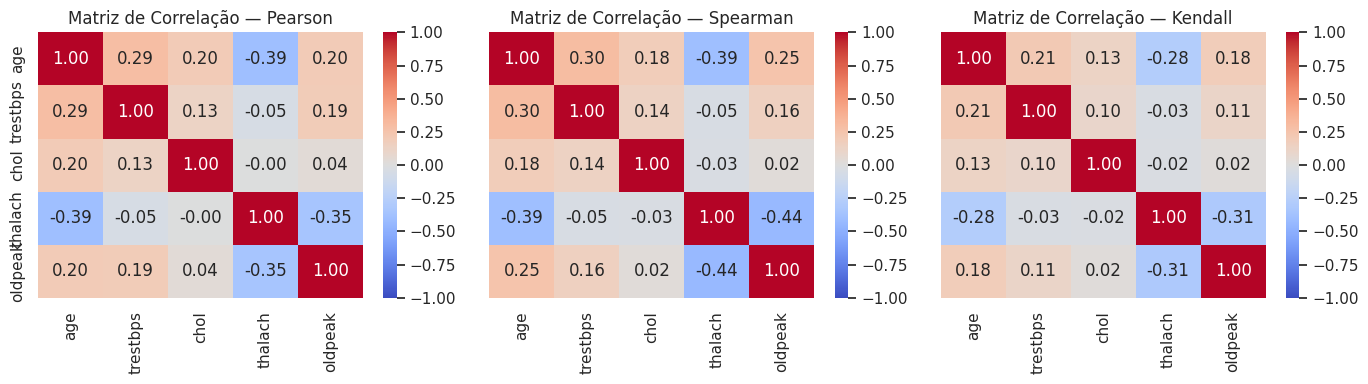

In [ ]:
corr_pearson = df[VARS_QUANT].corr(method="pearson")
corr_spearman = df[VARS_QUANT].corr(method="spearman")
corr_kendall = df[VARS_QUANT].corr(method="kendall")

fig, ax = plt.subplots(1,3,figsize=(14, 4),sharey=True)
sns.heatmap(corr_pearson, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1, ax=ax[0])
ax[0].set_title("Matriz de Correlação — Pearson")
sns.heatmap(corr_spearman, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1, ax=ax[1])
ax[1].set_title("Matriz de Correlação — Spearman")
sns.heatmap(corr_kendall, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1, ax=ax[2])
ax[2].set_title("Matriz de Correlação — Kendall")
plt.tight_layout()
plt.show()


Como os dados do triângulo superior e inferior são simétricos, poderíamos plotar a matriz de correlação da seguinte forma.

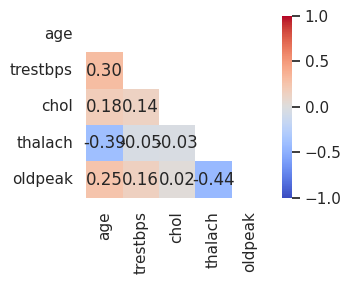

In [ ]:
mask = np.triu(np.ones_like(corr_spearman, dtype=bool))

plt.figure(figsize=(4, 3))
sns.heatmap(corr_spearman, mask=mask, annot=True, cmap="coolwarm", fmt=".2f", square=True, vmin=-1, vmax=1,)
plt.grid(False)

plt.tight_layout()
plt.show()

**Pra discutir:** Pearson e Spearman divergem bastante em algum par de variáveis? Se sim, isso é um sinal de relação não-linear (monotônica, mas não em linha reta) em que Spearman capturaria e Pearson não.

#### Dispersão (scatter) entre duas variáveis quantitativas

Escolhemos `age` x `thalach` por um motivo de domínio, não só estatístico: existe uma relação fisiológica entre idade e frequência cardíaca máxima, o que torna esse par um bom candidato pra visualizar uma tendência real.

**Nota para quando vocês replicarem no dataset de vocês:** nem sempre vai existir uma relação de domínio óbvia e, nesse caso, uma alternativa é escolher o par com o maior |correlação| na tabela acima, deixando a própria estatística guiar a escolha.

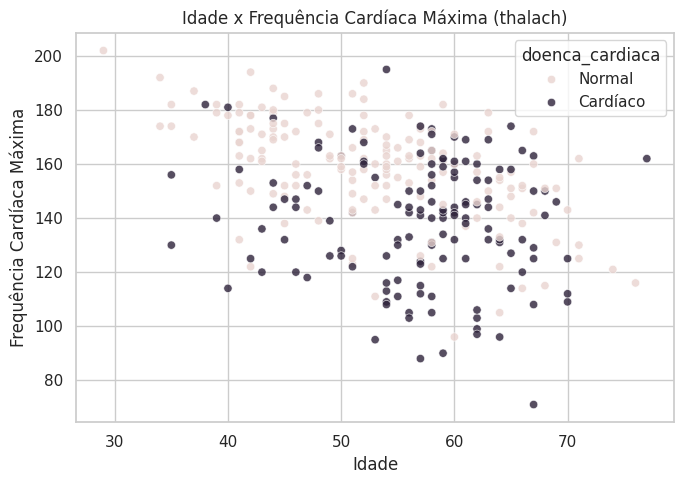

In [ ]:
plt.figure(figsize=(7, 5))
sns.scatterplot(data=df, x="age", y="thalach", hue="doenca_cardiaca",
                palette={"Normal": COR_CONTEXTO, "Cardíaco": COR_DESTAQUE}, alpha=0.8)
plt.title("Idade x Frequência Cardíaca Máxima (thalach)")
plt.xlabel("Idade")
plt.ylabel("Frequência Cardíaca Máxima")
plt.tight_layout()
plt.show()


**Pra discutir:** existe uma tendência visível (conforme a idade aumenta, `thalach` tende a cair)? As duas classes ocupam regiões diferentes do gráfico, ou estão misturadas?

#### Quantitativa x Qualitativa: Comparando Grupos

Na aula passada listamos **T-Test** (2 grupos) e **ANOVA** (3+ grupos) como testes paramétricos pra comparar uma variável quantitativa entre categorias, mas os dois assumem normalidade dentro de cada grupo.

Já vimos na Seção 3 (tabela generalizada do Shapiro-Wilk) que **nenhuma** das nossas quantitativas passou nesse teste. Isso significa que, tecnicamente, deveríamos usar os equivalentes **não-paramétricos**: **Mann-Whitney U** no lugar do T-Test, e **Kruskal-Wallis** no lugar da ANOVA. Vamos calcular os dois lado a lado pra comparar, mas o resultado não-paramétrico é o que deveríamos reportar como principal.

In [ ]:
resultados_comparacao = []
for col in VARS_QUANT:
    grupo_normal = df.loc[df["doenca_cardiaca"] == "Normal", col]
    grupo_cardiaco = df.loc[df["doenca_cardiaca"] == "Cardíaco", col]

    stat_t, p_t = stats.ttest_ind(grupo_normal, grupo_cardiaco, equal_var=False)  # Welch (paramétrico)
    stat_u, p_u = stats.mannwhitneyu(grupo_normal, grupo_cardiaco)                 # não-paramétrico

    resultados_comparacao.append({
        "variavel": col,
        "p_valor_ttest": round(p_t, 5),
        "p_valor_mannwhitney": round(p_u, 5),
        "concordam": (p_t < 0.05) == (p_u < 0.05),
    })

pd.DataFrame(resultados_comparacao).set_index("variavel")


,p_valor_ttest,p_valor_mannwhitney,concordam
variavel,,,
age,0.00006,0.00004,True
trestbps,0.00881,0.02346,True
chol,0.16501,0.04669,False
thalach,0.00000,0.00000,True
oldpeak,0.00000,0.00000,True


**Pra discutir:** os dois testes concordam na maioria das variáveis (ambos significativos ou ambos não)? Quando divergem, é o **Mann-Whitney** que deveríamos priorizar, é o que respeita a premissa que de fato temos (dados não-normais), não a que gostaríamos de ter.

**Nota:** mantivemos o T-Test aqui só como contraste pedagógico. Reportar apenas o T-Test, sem essa ressalva, seria estatisticamente inconsistente com o que a própria Seção 3 já mostrou sobre a normalidade dessas variáveis.

*Exemplo com 3+ grupos — ANOVA x Kruskal-Wallis*

`cp` (tipo de dor no peito) tem 4 categorias. Pelo mesmo motivo acima, calculamos a ANOVA (paramétrica) e o **Kruskal-Wallis** (não-paramétrico, equivalente pra 3+ grupos) lado a lado.

ANOVA          — thalach entre categorias de cp: estatística=17.771, p-valor=1.265e-10
Kruskal-Wallis — thalach entre categorias de cp: estatística=47.858, p-valor=2.283e-10


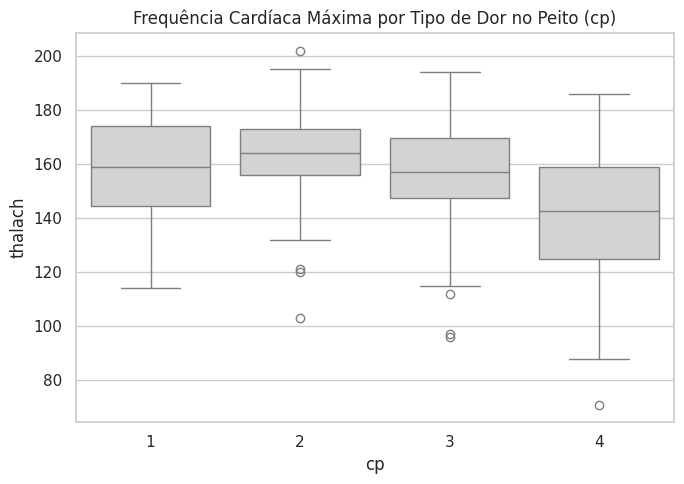

In [ ]:
grupos_cp = [grupo["thalach"].values for _, grupo in df.groupby("cp")]

stat_anova, p_anova = stats.f_oneway(*grupos_cp)   # paramétrico
stat_kw, p_kw = stats.kruskal(*grupos_cp)          # não-paramétrico

print(f"ANOVA          — thalach entre categorias de cp: estatística={stat_anova:.3f}, p-valor={p_anova:.5g}")
print(f"Kruskal-Wallis — thalach entre categorias de cp: estatística={stat_kw:.3f}, p-valor={p_kw:.5g}")

plt.figure(figsize=(7, 5))
sns.boxplot(data=df, x="cp", y="thalach", color=COR_NEUTRA)
plt.title("Frequência Cardíaca Máxima por Tipo de Dor no Peito (cp)")
plt.tight_layout()
plt.show()

**Pra discutir:** o Kruskal-Wallis concorda com a ANOVA sobre existir diferença entre pelo menos uma categoria de `cp`? Como já sabemos que `thalach` não é normal, o **Kruskal-Wallis** é o resultado que deveríamos reportar como principal, a ANOVA fica só como contraste.

#### Quantitativa x Qualitativa

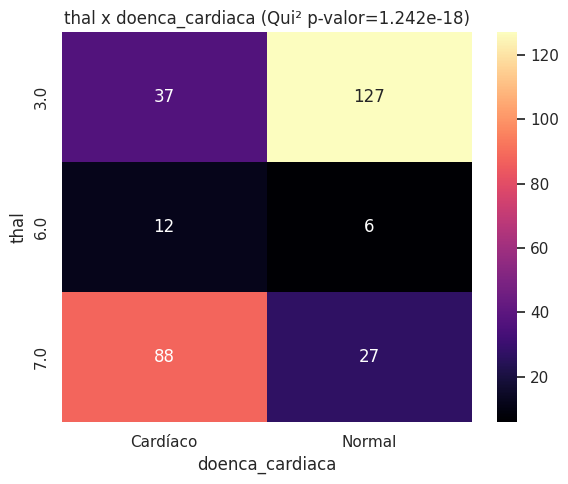

In [ ]:
contingencia_thal = pd.crosstab(df["thal"], df["doenca_cardiaca"])
chi2, p_chi2, gl, esperado = stats.chi2_contingency(contingencia_thal)

fig, ax = plt.subplots(figsize=(6, 5))
sns.heatmap(contingencia_thal, annot=True, fmt="d", cmap="magma", ax=ax)
ax.set_title(f"thal x doenca_cardiaca (Qui² p-valor={p_chi2:.4g})")
plt.tight_layout()
plt.show()


**Pra discutir:** o p-valor do Qui-Quadrado indica que `thal` e `doenca_cardiaca` são independentes, ou há associação estatisticamente significativa entre elas?

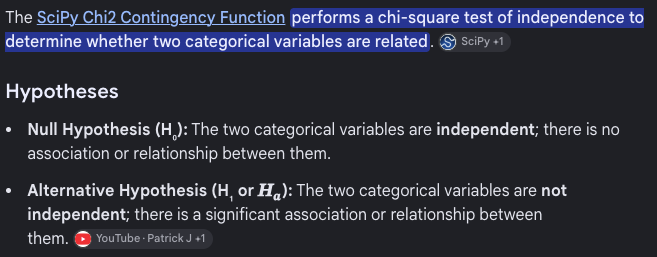

#### Avaliação de Fairness

Olhar o desbalanceamento da base inteira é só metade da história. Uma pergunta recorrente em discussões de **fairness** (justiça algorítmica) é: será que a distribuição do desfecho se comporta igual em diferentes subgrupos de atributos sensíveis (sexo e faixa etária, no nosso caso)? Se não, isso pode refletir um padrão real (ex: idade avançada é fator de risco documentado) ou um viés na forma como os dados foram coletados — de qualquer forma, é algo que vale mapear **antes** de qualquer modelagem.

In [ ]:
ct = pd.crosstab(df["Weather"], df["status_voo"], normalize="index") * 100
ct = ct[["No Horário", "Atrasado"]]
ax = ct.plot(kind="bar", stacked=True, color=[COR_CONTEXTO, COR_DESTAQUE], edgecolor="none")
plt.title("Proporção de Status do Voo por Condição Climática")
plt.ylabel("% de voos")
plt.xlabel("")
plt.xticks(rotation=0)
plt.legend(title="Status do Voo", bbox_to_anchor=(1.02, 1), loc="upper left", frameon=False)
sns.despine()

for container in ax.containers:
    ax.bar_label(container, fmt="%.0f%%", label_type="center")

plt.tight_layout()
plt.show()


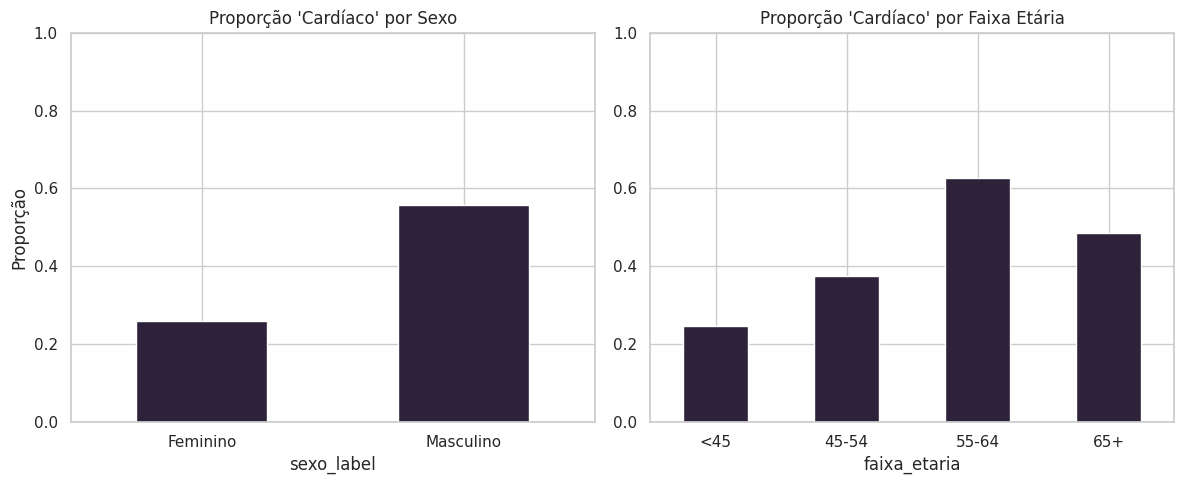

In [ ]:
prop_por_sexo = pd.crosstab(df["sexo_label"], df["doenca_cardiaca"], normalize="index").round(3)
prop_por_faixa = pd.crosstab(df["faixa_etaria"], df["doenca_cardiaca"], normalize="index").round(3)

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

prop_por_sexo["Cardíaco"].plot(kind="bar", color=COR_DESTAQUE, ax=axes[0])
axes[0].set_title("Proporção 'Cardíaco' por Sexo")
axes[0].set_ylabel("Proporção")
axes[0].set_ylim(0, 1)
axes[0].tick_params(axis="x", rotation=0)

prop_por_faixa["Cardíaco"].plot(kind="bar", color=COR_DESTAQUE, ax=axes[1])
axes[1].set_title("Proporção 'Cardíaco' por Faixa Etária")
axes[1].set_ylim(0, 1)
axes[1].tick_params(axis="x", rotation=0)

plt.tight_layout()
plt.show()

**Pra discutir:** a proporção de diagnóstico positivo varia bastante entre sexo ou faixa etária? Isso pode refletir um padrão clínico real e bem documentado (ex: risco cardíaco cresce com a idade), ou pode ser um artefato de **quem** foi encaminhado para o exame nesses hospitais específicos? A pergunta "a distribuição do desfecho é uniforme entre grupos protegidos?" é o ponto de partida de várias discussões de fairness em ciência de dados, e não tem uma resposta única: depende do contexto e da causa por trás da disparidade.

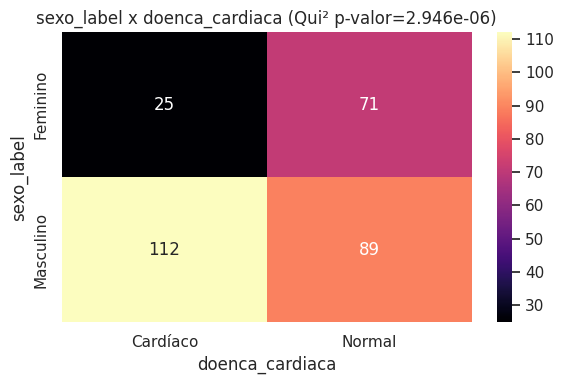

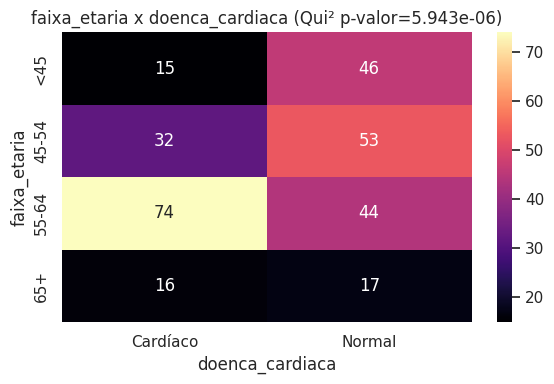

In [ ]:
for atributo in ["sexo_label", "faixa_etaria"]:
    contingencia = pd.crosstab(df[atributo], df["doenca_cardiaca"])
    chi2, p_valor, gl, esperado = stats.chi2_contingency(contingencia)

    fig, ax = plt.subplots(figsize=(6, 4))
    sns.heatmap(contingencia, annot=True, fmt="d", cmap="magma", ax=ax)
    ax.set_title(f"{atributo} x doenca_cardiaca (Qui² p-valor={p_valor:.4g})")
    plt.tight_layout()
    plt.show()


**Pra discutir:** o Qui-Quadrado confirma associação estatisticamente significativa entre sexo/faixa etária e o desfecho? Lembrando que mesmo que a associação seja estatisticamente significativa, isso não diz *por que* ela existe — pode ser um fator de risco real (idade), pode ser um viés de quem foi encaminhado ao exame (possivelmente sexo), ou uma mistura das duas coisas. Um teste estatístico aponta *que* existe associação, não *a causa* dela — essa distinção é o núcleo de qualquer discussão séria de fairness.

#### Outliers bivariados

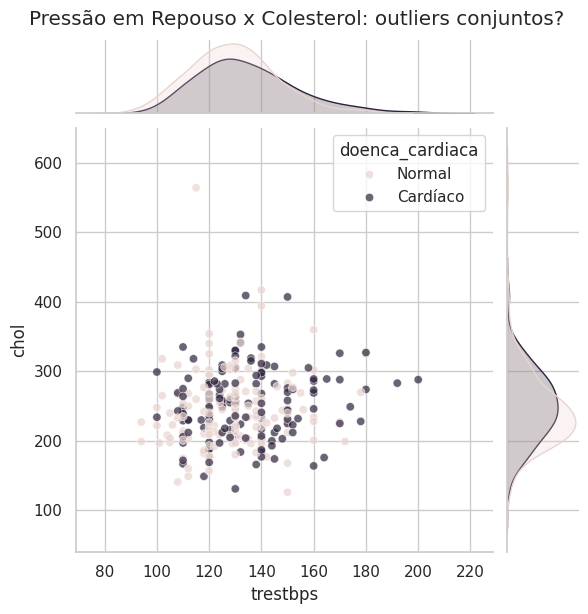

In [ ]:
sns.jointplot(data=df, x="trestbps", y="chol", hue="doenca_cardiaca",
              palette={"Normal": COR_CONTEXTO, "Cardíaco": COR_DESTAQUE}, alpha=0.7, height=6)
plt.suptitle("Pressão em Repouso x Colesterol: outliers conjuntos?", y=1.02)
plt.show()

**Pra discutir:** existe algum ponto que não parecia outlier nos histogramas univariados (Seção 3/4), mas que se destaca aqui como uma combinação incomum de `trestbps` e `chol`?

#### Análise Multivariada

##### Matriz de Correlação

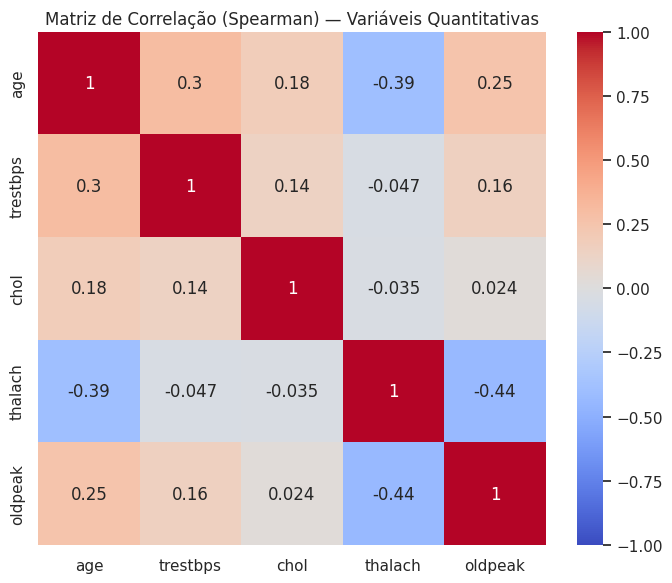

In [ ]:
plt.figure(figsize=(7, 6))
sns.heatmap(df[VARS_QUANT].corr(method="spearman"), annot=True, cmap="coolwarm", vmin=-1, vmax=1)
plt.title("Matriz de Correlação (Spearman) — Variáveis Quantitativas")
plt.tight_layout()
plt.show()


**Como interpretar:**


*   |r| < 0.3 ~ fraca,
*   0.3 < |r| < 0.7 ~ moderada,
*  |r| > 0.7 ~ forte.

Alguma correlação chama atenção por ser forte o suficiente pra sugerir redundância entre variáveis?

##### Correlograma

Text(0.5, 1.02, 'Correlograma: Dispersão × Correlação')

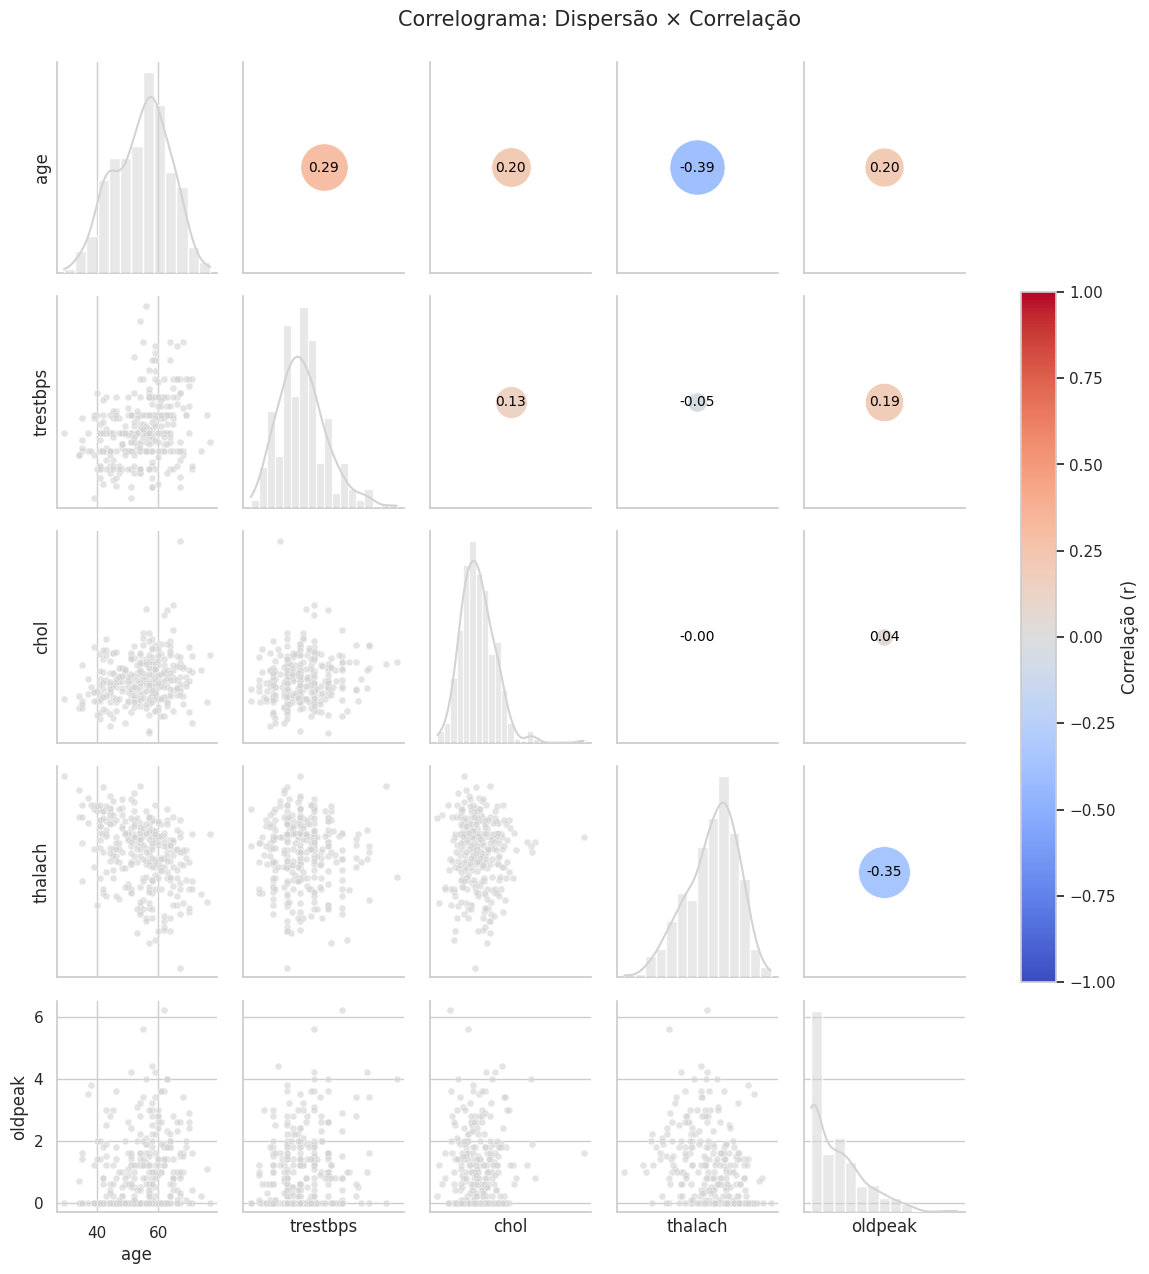

In [ ]:
from matplotlib.cm import ScalarMappable
from matplotlib.colors import Normalize

def circulo_correlacao(x, y, **kwargs):
    r = np.corrcoef(x, y)[0, 1]
    ax = plt.gca()
    ax.scatter(
        [0.5], [0.5],
        s=abs(r) * 4000,          # tamanho proporcional à força da correlação
        c=[r], cmap='coolwarm', vmin=-1, vmax=1,
        transform=ax.transAxes, edgecolor="white", linewidth=0.5,
    )
    ax.annotate(f"{r:.2f}", xy=(0.5, 0.5), xycoords=ax.transAxes,
                ha="center", va="center", fontsize=10,
                color="white" if abs(r) > 0.5 else "black")
    ax.set_xticks([]); ax.set_yticks([])
    ax.grid(False)

g = sns.PairGrid(df[VARS_QUANT], diag_sharey=False)
g.map_lower(sns.scatterplot, color=COR_NEUTRA, alpha=0.6, s=25)
g.map_diag(sns.histplot, color=COR_NEUTRA, kde=True)
g.map_upper(circulo_correlacao)

# barra de cor única, compartilhada (cada subplot superior tem seu próprio scatter)
sm = ScalarMappable(norm=Normalize(-1, 1), cmap='coolwarm')
sm.set_array([])
g.fig.colorbar(sm, ax=g.axes, shrink=0.6, label="Correlação (r)")

g.fig.suptitle("Correlograma: Dispersão × Correlação", y=1.02, fontsize=15)


## Hands-on!

Agora é a vez de você realizar uma EDA com os seu conjunto de dados recebidos.

Para isso crie um novo notebook e vamos fazer **em sala** uma EDA seguindo a aula prática que acabamos de ter. Os tópicos desenvolvidos são referências.

Para esse exercício é de suma importância que vocês **elaborem perguntas** e **discutam** os resultados obtidos. Por exemplo, se houver dados faltantes, busque *entender* o porquê e *justifique* sua decisão.

Após o desenvolvimento da EDA em si, é necessário fazer uma síntese considerando:


1.   Principais conclusões em 3 a 5 pontos
2.   Declaração de Uso de IA (Ferramenta utilizada, Para o que foi aplicada e o que foi aceito/modificado/rejeitado e por quê)

O **entregável** será um notebook `ipynb`que trará todo o código, discussão, principais conclusões e declaração de uso de IA.


